In [24]:
# STFT FROM SCRATCH
# import
import numpy as np
from scipy.signal import stft as scipy_stft
import matplotlib.pyplot as plt

In [25]:
def compute_hop(nperseg, hop_fraction=0.25):
    """
    Calcule la taille du 'hop' (déplacement en échantillons) et renvoie aussi le recouvrement.

    Paramètres
    ----------
    nperseg : int
        Taille de la fenêtre en échantillons (doit être >= 1).
    hop_fraction : float
        Fraction du nperseg correspondant au hop.
        - Doit être strictement entre 0.0 et 1.0 (exclu).
        - hop_fraction = hop / nperseg.
        - Exemple : hop_fraction=0.25 -> hop = 0.25*nperseg -> overlap = 0.75 (75% recouvrement).

    Retour
    ------
    hop : int
        Nombre d'échantillons de déplacement entre trames (>= 1 et <= nperseg).
    overlap : float
        Fraction de recouvrement entre 0 et <1 (overlap = 1 - hop_fraction).
    """
    # validations
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop_fraction, (int, float)):
        raise ValueError("hop_fraction doit être un nombre (float).")
    hop_fraction = float(hop_fraction)

    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction doit être dans l'intervalle (0.0, 1.0) une fraction quoi. "
                         "Exemples : 0.5 -> 50pourencent overlap (hop = nperseg*0.5), "
                         "0.25 -> 75% overlap (hop = nperseg*0.25).")

    # calcul du hop (arrondi au plus proche entiers)
    hop = int(round(nperseg * hop_fraction))

    # protections : s'assurer que hop est dans [1, nperseg]
    if hop < 1:
        hop = 1
    if hop > nperseg:
        hop = nperseg

    overlap = 1.0 - (hop / float(nperseg))

    return hop, overlap


In [26]:
# Test de compute hop---------------------------------------------------------------------------------------------------------
hop, overlap = compute_hop(1024, 0.5)
if hop == 512 and overlap == 0.5:
    print("ok 1")
else:
    print("not good 1")

hop, overlap = compute_hop(2048, 0.25)
if hop == 512 and overlap == 0.75:
    print("ok 2")
else:
    print("not good 2")

hop, overlap = compute_hop(1024, 0.1)
if hop == 102 and abs(overlap - 0.9) < 1e-3:
    print("ok 3")
else:
    print(f"not good 3, hop =  {hop}, overlap = {overlap}")
    
# Test 4: hop_fraction très petit
hop, overlap = compute_hop(1000, 0.001)
# hop devrait être 1 (minimum)
if hop == 1 and overlap == 0.999:
    print("ok 4 - hop_fraction très petit")
else:
    print(f"not good 4: hop={hop}, overlap={overlap}")

# Test 5: hop_fraction très grand
hop, overlap = compute_hop(1000, 0.999)
# hop devrait être 999 (nperseg-1)
if hop == 999 and abs(overlap - 0.001) < 1e-3:
    print("ok 5 - hop_fraction très grand")
else:
    print(f"not good 5: hop={hop}, overlap={overlap}")

# Test 6: nperseg = 1 (cas limite)
hop, overlap = compute_hop(1, 0.5)
# hop doit être 1 (seule valeur possible)
if hop == 1 and overlap == 0.0:
    print("ok 6 - nperseg = 1")
else:
    print(f"not good 6: hop={hop}, overlap={overlap}")

# Test 7: nperseg = 2
hop, overlap = compute_hop(2, 0.25)
# 2 * 0.25 = 0.5 → arrondi à 1
if hop == 1 and overlap == 0.5:
    print("ok 7 - nperseg = 2")
else:
    print(f"not good 7: hop={hop}, overlap={overlap}")

# Test 8: validation des entrées (doit lever une exception)
try:
    hop, overlap = compute_hop(0, 0.5)
    print("not good 8 - devrait lever ValueError pour nperseg=0")
except ValueError:
    print("ok 8 - ValueError levée pour nperseg=0")

# Test 9: hop_fraction hors limites
try:
    hop, overlap = compute_hop(1024, 0.0)
    print("not good 9.1 - devrait lever ValueError pour hop_fraction=0.0")
except ValueError:
    print("ok 9.1 - ValueError levée pour hop_fraction=0.0")

try:
    hop, overlap = compute_hop(1024, 1.0)
    print("not good 9.2 - devrait lever ValueError pour hop_fraction=1.0")
except ValueError:
    print("ok 9.2 - ValueError levée pour hop_fraction=1.0")
    


ok 1
ok 2
ok 3
ok 4 - hop_fraction très petit
ok 5 - hop_fraction très grand
ok 6 - nperseg = 1
ok 7 - nperseg = 2
ok 8 - ValueError levée pour nperseg=0
ok 9.1 - ValueError levée pour hop_fraction=0.0
ok 9.2 - ValueError levée pour hop_fraction=1.0


In [27]:
# Framing
import numpy as np

def framing(x, nperseg, hop):
    """
    Découpe le signal 1D `x` en trames (frames) successives.

    Paramètres
    ----------
    x : ndarray 1D
        Signal d'entrée (supposée mono).
    nperseg : int
        Taille de chaque frame en échantillons (>=1).
    hop : int
        Déplacement en échantillons entre le début de deux frames (>=1, <= nperseg).

    Remarques
    ---------
    - Cette version simplifiée FORCE le padding de la fin du signal (padding constant à zéro)
      afin que la dernière frame soit complète : on n'accepte plus d'options pour le padding.
      
    - Le pad_mode est fixé à 'constant' (zéros).
    - Le comportement garantit au moins une frame si le signal est plus court que nperseg.
    """

    # validations simples
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")
    if not isinstance(hop, int) or hop < 1:
        raise ValueError("hop doit être un entier >= 1.")
    if hop > nperseg:
        raise ValueError("hop ne peut pas être supérieur à nperseg.")
    if x.ndim != 1:
        raise ValueError("x doit être un tableau 1D (signal mono).")

    N = len(x)
    if N == 0:
        return np.zeros((0, nperseg), dtype=x.dtype), np.zeros((0,), dtype=int)

    # --- calcul du nombre de frames (padding forcé à la fin, pad_mode='constant') ---
    # on autorise la dernière fenêtre à démarrer avant la fin et on complète si nécessaire
    n_frames_calc = int(np.floor((N - nperseg) / float(hop))) + 1
    # garantir au moins 1 frame (cas len(x) < nperseg)
    n_frames = max(1, n_frames_calc)

    # indices de départ
    starts = np.arange(n_frames) * hop

    # padding constant à la fin si nécessaire (pad_mode = 'constant')
    last_needed = starts[-1] + nperseg
    if last_needed > N:
        pad_len = last_needed - N
        x_padded = np.pad(x, (0, pad_len), mode='constant')
    else:
        x_padded = x

    # construire les frames
    frames = np.empty((n_frames, nperseg), dtype=x_padded.dtype)
    for i, s in enumerate(starts):
        frames[i, :] = x_padded[s : s + nperseg]

    return frames, starts


In [28]:
# Test unitaire co-redigé avec grok
def run_framing_tests(framing_fn):
    """
    Tests unitaires essentiels pour framing(x, nperseg, hop).
    Focus sur : formes, dtype, valeurs, erreurs, et padding constant forcé.
    """
    passed = 0
    total = 0

    def test(cond, msg):
        nonlocal passed, total
        total += 1
        if cond:
            passed += 1
            print(f"OK: {msg}")
        else:
            raise AssertionError(f"Échec: {msg}")

    # Test 1 : Signal plus court que nperseg → 1 frame avec padding zéros
    x = np.arange(100.0)  # dtype float pour test
    nperseg = 256
    hop = 128
    frames, starts = framing_fn(x, nperseg, hop)
    test(frames.shape == (1, nperseg), "Une frame pour signal < nperseg")
    test(np.array_equal(starts, np.array([0])), "Start à 0")
    test(np.array_equal(frames[0, :len(x)], x), "Début de frame = x")
    test(np.all(frames[0, len(x):] == 0), "Padding zéros à la fin")

    # Test 2 : Signal exact multiple sans besoin de padding
    x = np.arange(1024)
    nperseg = 256
    hop = 256  # Pas d'overlap
    frames, starts = framing_fn(x, nperseg, hop)
    test(frames.shape == (4, 256), "4 frames pour signal=1024, nperseg=256, hop=256")
    test(np.array_equal(starts, np.array([0, 256, 512, 768])), "Starts corrects")

    # Test 3 : Avec overlap (recouvrement)
    x = np.arange(40)
    nperseg = 8
    hop = 2  # 75% overlap
    frames, starts = framing_fn(x, nperseg, hop)
    expected_nframes = 1 + int(np.floor((len(x) - nperseg) / hop))
    test(frames.shape[0] == expected_nframes, f"{expected_nframes} frames avec overlap")
    for i, s in enumerate(starts):
        test(frames[i, 0] == x[s], f"Frame {i} commence par x[{s}]")

    # Test 4 : dtype préservé
    x_int = np.arange(300, dtype=np.int16)
    nperseg = 128
    hop = 64
    frames, starts = framing_fn(x_int, nperseg, hop)
    test(frames.dtype == np.int16, "dtype préservé (int16)")

    # Test 5 : Erreurs d'entrée
    try:
        framing_fn(np.arange(10), nperseg=8, hop=9)  # hop > nperseg
        test(False, "hop > nperseg ne lève pas ValueError")  # Devrait échouer si pas levé
    except ValueError:
        test(True, "hop > nperseg lève ValueError")

    try:
        framing_fn(np.ones((2, 3)), nperseg=4, hop=2)  # x non 1D
        test(False, "x non-1D ne lève pas ValueError")
    except ValueError:
        test(True, "x non-1D lève ValueError")

    print(f"\nTests framing passés : {passed}/{total}")

# Appel exemple
run_framing_tests(framing)

OK: Une frame pour signal < nperseg
OK: Start à 0
OK: Début de frame = x
OK: Padding zéros à la fin
OK: 4 frames pour signal=1024, nperseg=256, hop=256
OK: Starts corrects
OK: 17 frames avec overlap
OK: Frame 0 commence par x[0]
OK: Frame 1 commence par x[2]
OK: Frame 2 commence par x[4]
OK: Frame 3 commence par x[6]
OK: Frame 4 commence par x[8]
OK: Frame 5 commence par x[10]
OK: Frame 6 commence par x[12]
OK: Frame 7 commence par x[14]
OK: Frame 8 commence par x[16]
OK: Frame 9 commence par x[18]
OK: Frame 10 commence par x[20]
OK: Frame 11 commence par x[22]
OK: Frame 12 commence par x[24]
OK: Frame 13 commence par x[26]
OK: Frame 14 commence par x[28]
OK: Frame 15 commence par x[30]
OK: Frame 16 commence par x[32]
OK: dtype préservé (int16)
OK: hop > nperseg lève ValueError
OK: x non-1D lève ValueError

Tests framing passés : 27/27


In [29]:
# la forme de notre fenetre qu'on va faire glisser sur le signal
def get_window(window_name="hann", nperseg=1024):
    """
    Génère une fenêtre temps de longueur `nperseg`.

    Paramètres
    ----------
    window_name : str
        Nom de la fenêtre souhaitée (insensible à la casse).
        Dans notre projet on n'utilise QUE :
            - 'hann' (recommandé pour STFT/ISTFT, respecte COLA avec hop = nperseg/2)

        Les autres fenêtres sont supprimées car :
            - 'rect' provoque des fuites spectrales
            - 'hamming', 'blackman', 'bartlett' compliquent la reconstruction
            - 'kaiser' inutile ici et nécessite un paramètre β
    nperseg : int
        Longueur de la fenêtre en échantillons (>= 1).

    Retour
    ------
    w : ndarray, shape (nperseg,)
        Vecteur fenêtre.

    Remarques / recommandations
    ---------------------------
    - 'hann' est un excellent compromis pour STFT et ISTFT.
      Avec hop = nperseg/2 → condition COLA vérifiée.
      (somme_k w[n - k*hop] = C)
    """

    # validations d'entrée
    if not isinstance(nperseg, int) or nperseg < 1:
        raise ValueError("nperseg doit être un entier >= 1.")

    # accepter seulement 'hann' qui est suffisant (je pense)
    wn = str(window_name).lower()
    if wn not in ('hann', 'hanning'):
        raise ValueError(
            "Seule la fenêtre 'hann' est supportée dans notre implémentation simplifiée."
        )

    
    if nperseg > 1:
        n = np.arange(nperseg)
        w = 0.5 - 0.5 * np.cos(2.0 * np.pi * n / (nperseg - 1))
    else:
        w = np.array([1.0])

    return w.astype(float)


In [30]:
# Teste unitaire co-redigé avec chatg
def run_get_window_tests(get_window_fn):
    """
    Tests unitaires basiques pour la version simplifiée de get_window().
    get_window_fn doit avoir la signature : get_window(window_name='hann', nperseg=1024)
    """
    passed = 0
    total = 0

    def expect(cond, msg):
        nonlocal passed, total
        total += 1
        if not cond:
            raise AssertionError(f"Test échoué : {msg}")
        passed += 1
        print("OK:", msg)

    # Test 1 : forme et type de retour pour nperseg classique
    w = get_window_fn(window_name="hann", nperseg=1024)
    expect(isinstance(w, np.ndarray), "retour est un ndarray")
    expect(w.shape == (1024,), "shape correcte (1024,)")
    expect(w.dtype == float or np.issubdtype(w.dtype, np.floating), "dtype flottant")

    # Test 2 : valeurs attendues - hann est non-négative et bord = 0 (si nperseg>1)
    expect(np.all(w >= 0), "tous les éléments sont >= 0")
    expect(abs(w[0]) < 1e-12 and abs(w[-1]) < 1e-12, "valeurs aux bords ≈ 0 pour nperseg>1")

    # Test 3 : nperseg == 1 -> retourne [1.0]
    w1 = get_window_fn(window_name="hann", nperseg=1)
    expect(w1.shape == (1,), "nperseg=1 -> shape (1,)")
    expect(w1[0] == 1.0, "nperseg=1 -> valeur 1.0")

    # Test 4 : reproductibilité / symétrie (Hann est symétrique)
    w_small = get_window_fn(window_name="hann", nperseg=11)
    # symétrie : w[i] == w[-1-i]
    symmetric = np.allclose(w_small, w_small[::-1], atol=1e-12)
    expect(symmetric, "Hann doit être symétrique")

    # Test 5 : erreur sur window_name non supporté
    raised = False
    try:
        get_window_fn(window_name="hamming", nperseg=256)
    except ValueError:
        raised = True
    expect(raised, "window_name non supporté doit lever ValueError (hamming)")

    # Test 6 : erreur sur nperseg invalide
    raised = False
    try:
        get_window_fn(window_name="hann", nperseg=0)
    except ValueError:
        raised = True
    expect(raised, "nperseg=0 doit lever ValueError")

            # Test 7 : propriété COLA pour hop = nperseg//2 (overlap-add approx constante)
    for N in (64, 128, 256):
        hop = N // 2
        wN = get_window_fn(window_name="hann", nperseg=N)
        n_frames = 20
        total_len = (n_frames - 1) * hop + N
        sum_array = np.zeros(total_len, dtype=float)
        starts = np.arange(0, n_frames * hop, hop)
        for s in starts:
            sum_array[s:s+N] += wN

        # portion centrale (éviter les effets de bord)
        center = sum_array[N:-N] if len(sum_array) > 2 * N else sum_array.copy()

        # Mesure 1 : variance relative (tolérance relâchée)
        rel_var = np.var(center) / (np.mean(center)**2 + 1e-20)
        expect(rel_var < 1e-4, f"COLA approx constante pour N={N}, rel_var={rel_var:.2e}")

        # Mesure 2 : amplitude relative (max-min)/mean avec tolérance adaptative
        rel_range = (np.max(center) - np.min(center)) / (np.mean(center) + 1e-20)

        # tolérance adaptative basée sur la loi empirique rel_range ~ C / N (C≈1.57)
        tol = max(1e-3, 2.0 / float(N))  # factor 2 for safety

        print(f"DEBUG COLA N={N}: rel_var={rel_var:.2e}, rel_range={rel_range:.2e}, tol={tol:.2e}")
        expect(rel_range < tol, f"COLA amplitude relative for N={N} too large: rel_range={rel_range:.2e} (tol={tol:.2e})")




    print(f"\nTous les tests get_window sont passés : {passed}/{total} OK")

# Exemple d'appel :
run_get_window_tests(get_window)


OK: retour est un ndarray
OK: shape correcte (1024,)
OK: dtype flottant
OK: tous les éléments sont >= 0
OK: valeurs aux bords ≈ 0 pour nperseg>1
OK: nperseg=1 -> shape (1,)
OK: nperseg=1 -> valeur 1.0
OK: Hann doit être symétrique
OK: window_name non supporté doit lever ValueError (hamming)
OK: nperseg=0 doit lever ValueError
OK: COLA approx constante pour N=64, rel_var=6.37e-05
DEBUG COLA N=64: rel_var=6.37e-05, rel_range=2.47e-02, tol=3.12e-02
OK: COLA amplitude relative for N=64 too large: rel_range=2.47e-02 (tol=3.12e-02)
OK: COLA approx constante pour N=128, rel_var=1.51e-05
DEBUG COLA N=128: rel_var=1.51e-05, rel_range=1.23e-02, tol=1.56e-02
OK: COLA amplitude relative for N=128 too large: rel_range=1.23e-02 (tol=1.56e-02)
OK: COLA approx constante pour N=256, rel_var=3.67e-06
DEBUG COLA N=256: rel_var=3.67e-06, rel_range=6.15e-03, tol=7.81e-03
OK: COLA amplitude relative for N=256 too large: rel_range=6.15e-03 (tol=7.81e-03)

Tous les tests get_window sont passés : 16/16 OK


In [31]:
def apply_window(frames, window):
    """
    Applique une fenêtre à chaque trame.

    Paramètres
    ----------
    frames : ndarray (n_frames, nperseg)
        Trames du signal
    window : ndarray (nperseg,)
        Vecteur fenêtre

    Retour
    ------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (element-wise multiplication)
    
    Exemple
    -------
    >>> frames = np.array([[1, 2, 3], [4, 5, 6]])
    >>> window = np.array([0.5, 1.0, 0.5])
    >>> apply_window(frames, window)
    array([[0.5, 2. , 1.5],
           [2. , 5. , 3. ]])
    """
    # Validation des dimensions
    if frames.ndim != 2:
        raise ValueError(f"frames doit être 2D, shape reçu: {frames.shape}")
    if window.ndim != 1:
        raise ValueError(f"window doit être 1D, shape reçu: {window.shape}")
    if frames.shape[1] != window.shape[0]:
        raise ValueError(
            f"Dimension incompatible: frames.shape[1]={frames.shape[1]} "
            f"mais window.shape[0]={window.shape[0]}"
        )
    
    # Multiplication élément par élément (broadcasting)
    return frames * window

In [32]:
# Teste unitaire co-redigé avec deepseek
def test_apply_window():
    """Tests basiques pour apply_window"""
    
    print("=== Test apply_window ===")
    
    # Test 1: Cas simple
    frames = np.array([[1.0, 2.0, 3.0], 
                       [4.0, 5.0, 6.0]])
    window = np.array([0.5, 1.0, 0.5])
    result = apply_window(frames, window)
    expected = np.array([[0.5, 2.0, 1.5],
                         [2.0, 5.0, 3.0]])
    
    if np.allclose(result, expected):
        print("✓ Test 1 passé: multiplication simple")
    else:
        print("✗ Test 1 échoué")
        print(f"  Résultat: {result}")
        print(f"  Attendue: {expected}")
    
    # Test 2: Fenêtre de Hann (valeurs entre 0 et 1)
    nperseg = 8
    window_hann = get_window("hann", nperseg)
    frames_random = np.random.randn(10, nperseg)  # 10 trames aléatoires
    windowed = apply_window(frames_random, window_hann)
    
    # Vérifier que le résultat a la bonne forme
    if windowed.shape == (10, nperseg):
        print("✓ Test 2 passé: shape préservée")
    else:
        print(f"✗ Test 2 échoué: shape {windowed.shape} au lieu de (10, {nperseg})")
    
    # Test 3: Vérifier que chaque élément est bien multiplié
    # Pour une trame i et un échantillon j: result[i,j] = frames[i,j] * window[j]
    i, j = 3, 2  # indices arbitraires
    expected_val = frames_random[i, j] * window_hann[j]
    if abs(windowed[i, j] - expected_val) < 1e-10:
        print("✓ Test 3 passé: multiplication correcte par élément")
    else:
        print(f"✗ Test 3 échoué: {windowed[i,j]} ≠ {expected_val}")
    
    # Test 4: Gestion d'erreur - dimensions incompatibles
    try:
        bad_window = np.array([0.5, 1.0])  # taille 2 au lieu de 8
        apply_window(frames_random, bad_window)
        print("✗ Test 4 échoué: devrait lever ValueError")
    except ValueError as e:
        print(f"✓ Test 4 passé: ValueError levée: {str(e)[:50]}...")
    
    # Test 5: Gestion d'erreur - frames 1D
    try:
        apply_window(np.array([1, 2, 3]), window_hann)
        print("✗ Test 5 échoué: devrait lever ValueError pour frames 1D")
    except ValueError:
        print("✓ Test 5 passé: ValueError pour frames 1D")
    
    print("=== Fin tests apply_window ===\n")

# Exécuter les tests
test_apply_window()

=== Test apply_window ===
✓ Test 1 passé: multiplication simple
✓ Test 2 passé: shape préservée
✓ Test 3 passé: multiplication correcte par élément
✓ Test 4 passé: ValueError levée: Dimension incompatible: frames.shape[1]=8 mais win...
✓ Test 5 passé: ValueError pour frames 1D
=== Fin tests apply_window ===



In [33]:
def fft_frames(windowed_frames, nfft=None, fs=1.0):
    """
    Applique la FFT réelle (rFFT) à chaque trame fenêtrée.

    Paramètres
    ----------
    windowed_frames : ndarray (n_frames, nperseg)
        Trames fenêtrées (signal réel).
    nfft : int ou None
        Taille de la FFT. Si None, nfft = nperseg.
        Si nfft > nperseg, zero-padding est appliqué.
    fs : float
        Fréquence d'échantillonnage en Hz (pour calculer les fréquences).
        Par défaut 1.0 (fréquences normalisées).

    Retour
    ------
    STFT : ndarray complex (n_frames, n_freq_bins)
        Transformée de Fourier par trame.
        n_freq_bins = nfft//2 + 1 (rFFT pour signaux réels).
    freqs : ndarray (n_freq_bins,)
        Fréquences en Hz correspondant aux bins de fréquence.

    Notes
    -----
    - Utilise np.fft.rfft() qui est optimisé pour les signaux réels.
    - n_freq_bins = nfft//2 + 1 (ex: nfft=1024 → 513 bins de fréquence).
    - La fréquence de Nyquist est fs/2 (incluse si nfft est pair).
    """
    # Validation des entrées
    if windowed_frames.ndim != 2:
        raise ValueError(f"windowed_frames doit être 2D, shape reçu: {windowed_frames.shape}")
    
    n_frames, nperseg = windowed_frames.shape
    
    # Déterminer nfft
    if nfft is None:
        nfft = nperseg
    elif nfft < nperseg:
        raise ValueError(f"nfft ({nfft}) ne peut pas être < nperseg ({nperseg})")
    elif nfft <= 0:
        raise ValueError(f"nfft doit être > 0, reçu: {nfft}")
    
    if fs <= 0:
        raise ValueError(f"fs doit être > 0, reçu: {fs}")
    
    # Appliquer la FFT réelle (rfft) sur chaque trame
    # axis=1 : FFT le long des colonnes (pour chaque trame)
    STFT = np.fft.rfft(windowed_frames, n=nfft, axis=1) # supposé 1d
    
    # np.fft.rfftfreq(nfft, d=1/fs) donne les fréquences pour un rfft
    freqs = np.fft.rfftfreq(nfft, d=1.0/fs)
    
    return STFT, freqs

In [34]:
def test_fft_frames():
    """Tests unitaires pour fft_frames"""
    
    print("=== Test fft_frames ===")
    
    # Test 1: Signal simple - sinus pur
    fs = 1000.0
    duration = 0.1  # 100 ms
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    f_signal = 100.0  # Hz
    x = np.sin(2 * np.pi * f_signal * t)
    
    # Découper en trames
    nperseg = 256
    hop = 128
    frames, starts = framing(x, nperseg, hop)
    
    # Fenêtrer
    window = get_window("hann", nperseg)
    windowed = apply_window(frames, window)
    
    # Appliquer FFT
    STFT, freqs = fft_frames(windowed, nfft=nperseg, fs=fs)
    
    # Vérifications
    n_frames, n_freqs = STFT.shape
    print(f"✓ Test 1: STFT shape = ({n_frames}, {n_freqs})")
    print(f"  Nombre de bins de fréquence: {n_freqs} (attendu: {nperseg//2 + 1})")
    
    # Vérifier que la fréquence du signal est présente
    freq_idx = np.argmin(np.abs(freqs - f_signal))
    print(f"  Fréquence signal: {f_signal} Hz, bin le plus proche: {freqs[freq_idx]:.1f} Hz")
    
    # Vérifier que l'amplitude est maximale à la fréquence du signal
    # (prendre la magnitude moyenne sur toutes les trames)
    magnitude = np.abs(STFT).mean(axis=0)
    max_idx = np.argmax(magnitude)
    print(f"  Fréquence avec magnitude max: {freqs[max_idx]:.1f} Hz")
    
    # Test 2: Vérification des fréquences
    expected_n_freqs = nperseg // 2 + 1
    if len(freqs) == expected_n_freqs:
        print("✓ Test 2: Nombre correct de bins de fréquence")
    else:
        print(f"✗ Test 2: {len(freqs)} bins au lieu de {expected_n_freqs}")
    
    # Vérifier que les fréquences sont croissantes
    if np.all(np.diff(freqs) > 0):
        print("✓ Test 3: Les fréquences sont strictement croissantes")
    else:
        print("✗ Test 3: Les fréquences ne sont pas croissantes")
    
    # Test 4: Fréquence de Nyquist
    nyquist = fs / 2.0
    if np.isclose(freqs[-1], nyquist):
        print(f"✓ Test 4: Fréquence de Nyquist correcte: {freqs[-1]:.1f} Hz")
    else:
        print(f"✗ Test 4: Nyquist: {freqs[-1]:.1f} Hz au lieu de {nyquist:.1f} Hz")
    
    # Test 5: Zero-padding
    nfft_padded = 512  # > nperseg
    STFT_padded, freqs_padded = fft_frames(windowed, nfft=nfft_padded, fs=fs)
    expected_padded_freqs = nfft_padded // 2 + 1
    
    if STFT_padded.shape[1] == expected_padded_freqs:
        print(f"✓ Test 5: Zero-padding fonctionnel - {STFT_padded.shape[1]} bins")
    else:
        print(f"✗ Test 5: {STFT_padded.shape[1]} bins au lieu de {expected_padded_freqs}")
    
    # Test 6: Gestion d'erreur - nfft < nperseg
    try:
        fft_frames(windowed, nfft=128, fs=fs)  # 128 < 256
        print("✗ Test 6: Devrait lever ValueError pour nfft < nperseg")
    except ValueError:
        print("✓ Test 6: ValueError levée pour nfft < nperseg")
    
    # Test 7: Gestion d'erreur - entrée 1D
    try:
        fft_frames(np.array([1, 2, 3]), fs=fs)
        print("✗ Test 7: Devrait lever ValueError pour entrée 1D")
    except ValueError:
        print("✓ Test 7: ValueError levée pour entrée 1D")
    
    # Test 8: Vérifier que le résultat est complexe
    if np.iscomplexobj(STFT):
        print("✓ Test 8: STFT est de type complexe")
    else:
        print("✗ Test 8: STFT n'est pas complexe")
    
    print("=== Fin tests fft_frames ===\n")

# Exécuter les tests
test_fft_frames()

=== Test fft_frames ===
✓ Test 1: STFT shape = (1, 129)
  Nombre de bins de fréquence: 129 (attendu: 129)
  Fréquence signal: 100.0 Hz, bin le plus proche: 101.6 Hz
  Fréquence avec magnitude max: 101.6 Hz
✓ Test 2: Nombre correct de bins de fréquence
✓ Test 3: Les fréquences sont strictement croissantes
✓ Test 4: Fréquence de Nyquist correcte: 500.0 Hz
✓ Test 5: Zero-padding fonctionnel - 257 bins
✓ Test 6: ValueError levée pour nfft < nperseg
✓ Test 7: ValueError levée pour entrée 1D
✓ Test 8: STFT est de type complexe
=== Fin tests fft_frames ===



In [35]:
def magnitude_or_power(STFT, kind="magnitude"):
    """
    Convertit la STFT complexe en magnitude ou puissance.
    """
    if kind == "magnitude":
        return np.abs(STFT)
    elif kind == "power":
        return np.abs(STFT) ** 2
    else:
        raise ValueError("kind doit être 'magnitude' ou 'power'")

In [36]:
# teste unitaire magnitude_or_power co-redigé deepseek
def test_magnitude_or_power():
    """
    Tests unitaires pour magnitude_or_power()
    """
    print("=== Test magnitude_or_power ===")
    
    passed = 0
    total = 0
    
    def test(condition, message):
        nonlocal passed, total
        total += 1
        if condition:
            passed += 1
            print(f"✓ {message}")
        else:
            print(f"✗ {message}")
    
    # Test 1: Cas simple avec un nombre complexe unique
    STFT_simple = np.array([[1 + 1j]], dtype=complex)
    
    # magnitude = sqrt(1² + 1²) = sqrt(2) ≈ 1.4142
    expected_magnitude = np.sqrt(2)
    result_magnitude = magnitude_or_power(STFT_simple, kind="magnitude")
    test(np.allclose(result_magnitude, expected_magnitude), 
         "Magnitude d'un nombre complexe simple")
    
    # power = (sqrt(2))² = 2
    expected_power = 2.0
    result_power = magnitude_or_power(STFT_simple, kind="power")
    test(np.allclose(result_power, expected_power), 
         "Puissance d'un nombre complexe simple")
    
    # Test 2: Vérifier que magnitude² = power
    test(np.allclose(result_magnitude**2, result_power),
         "Vérification: magnitude² = power")
    
    # Test 3: Tableau 2D avec valeurs aléatoires
    np.random.seed(42)  # Pour la reproductibilité
    STFT_random = np.random.randn(5, 10) + 1j * np.random.randn(5, 10)
    
    result_mag = magnitude_or_power(STFT_random, kind="magnitude")
    result_pow = magnitude_or_power(STFT_random, kind="power")
    
    # Vérifier la shape préservée
    test(result_mag.shape == STFT_random.shape, 
         "Shape préservée pour magnitude")
    test(result_pow.shape == STFT_random.shape, 
         "Shape préservée pour puissance")
    
    # Vérifier que les résultats sont réels
    test(not np.iscomplexobj(result_mag), 
         "Magnitude retourne un tableau réel")
    test(not np.iscomplexobj(result_pow), 
         "Puissance retourne un tableau réel")
    
    # Vérifier que tous les éléments sont >= 0 (module toujours positif)
    test(np.all(result_mag >= 0), 
         "Tous les éléments de magnitude sont >= 0")
    test(np.all(result_pow >= 0), 
         "Tous les éléments de puissance sont >= 0")
    
    # Vérifier la relation magnitude² = power pour quelques éléments
    random_indices = [(0,0), (2,5), (4,9)]
    for i, j in random_indices:
        mag_val = result_mag[i, j]
        pow_val = result_pow[i, j]
        test(np.isclose(mag_val**2, pow_val, rtol=1e-10),
             f"Relation magnitude²=power pour l'élément ({i},{j})")
    
    # Test 4: Vérifier avec des zéros
    STFT_zeros = np.zeros((3, 4), dtype=complex)
    result_mag_zeros = magnitude_or_power(STFT_zeros, kind="magnitude")
    result_pow_zeros = magnitude_or_power(STFT_zeros, kind="power")
    
    test(np.all(result_mag_zeros == 0), 
         "Magnitude de zéros = zéros")
    test(np.all(result_pow_zeros == 0), 
         "Puissance de zéros = zéros")
    
    # Test 5: Valeurs purement réelles
    STFT_real = np.array([[1.0, 2.0, 3.0], 
                          [4.0, 5.0, 6.0]], dtype=complex)
    result_mag_real = magnitude_or_power(STFT_real, kind="magnitude")
    expected_mag_real = np.array([[1.0, 2.0, 3.0], 
                                  [4.0, 5.0, 6.0]])
    
    test(np.allclose(result_mag_real, expected_mag_real),
         "Magnitude de valeurs purement réelles = valeur absolue")
    
    # Test 6: Valeurs purement imaginaires
    STFT_imag = np.array([[1j, 2j, 3j], 
                          [4j, 5j, 6j]], dtype=complex)
    result_mag_imag = magnitude_or_power(STFT_imag, kind="magnitude")
    expected_mag_imag = np.array([[1.0, 2.0, 3.0], 
                                  [4.0, 5.0, 6.0]])
    
    test(np.allclose(result_mag_imag, expected_mag_imag),
         "Magnitude de valeurs purement imaginaires = module")
    
    # Test 7: Gestion d'erreur - kind invalide
    try:
        magnitude_or_power(STFT_random, kind="invalid")
        test(False, "Devrait lever ValueError pour kind invalide")
    except ValueError as e:
        test("invalid" in str(e).lower() or "magnitude" in str(e).lower() or "power" in str(e).lower(),
             "ValueError levée pour kind invalide")
    
    # Test 8: Vérifier que c'est une opération élément par élément
    # Créer un STFT avec un pattern spécifique
    STFT_pattern = np.array([
        [1+0j, 0+1j, 1+1j],
        [2+0j, 0+2j, 2+2j]
    ])
    
    result_mag_pattern = magnitude_or_power(STFT_pattern, kind="magnitude")
    expected_pattern = np.array([
        [1.0, 1.0, np.sqrt(2)],
        [2.0, 2.0, np.sqrt(8)]  # sqrt(2²+2²) = sqrt(8)
    ])
    
    test(np.allclose(result_mag_pattern, expected_pattern),
         "Calcul élément par élément correct")
    
    # Test 9: Vérifier avec des valeurs très petites (stabilité numérique)
    STFT_small = np.array([[1e-10 + 1e-10j]], dtype=complex)
    result_mag_small = magnitude_or_power(STFT_small, kind="magnitude")
    expected_small = np.sqrt(2e-20)  # sqrt(2 * 10^-20)
    
    test(np.allclose(result_mag_small, expected_small, rtol=1e-10),
         "Précision numérique pour valeurs très petites")
    
    # Test 10: Vérifier avec des valeurs très grandes
    STFT_large = np.array([[1e10 + 1e10j]], dtype=complex)
    result_mag_large = magnitude_or_power(STFT_large, kind="magnitude")
    expected_large = np.sqrt(2e20)  # sqrt(2 * 10^20)
    
    test(np.allclose(result_mag_large, expected_large, rtol=1e-10),
         "Précision numérique pour valeurs très grandes")
    
    # Test 11: Vérifier que le dtype est préservé (float)
    test(result_mag.dtype in [np.float32, np.float64],
         "dtype float préservé")
    test(result_pow.dtype in [np.float32, np.float64],
         "dtype float préservé")
    
    print(f"\nRésumé: {passed}/{total} tests passés")
    print("=== Fin tests magnitude_or_power ===\n")
    
    return passed == total  # Retourne True si tous les tests passent

# ------------------------------------------Specifique a notre cas stft
def test_magnitude_or_power_stft_context():
    """
    Tests spécifiques pour magnitude_or_power() dans le contexte STFT
    """
    print("=== Tests STFT context pour magnitude_or_power ===")
    
    # Simuler un STFT typique (n_frames, n_freqs)
    n_frames = 10
    n_freqs = 513  # Typique pour nfft=1024 (1024//2 + 1)
    
    # Créer un STFT avec des caractéristiques réalistes
    # Fréquence fondamentale à la bin 50
    t = np.arange(n_frames)
    f_bin = 50
    
    # Créer un STFT avec une fréquence qui varie en amplitude
    STFT_stft = np.zeros((n_frames, n_freqs), dtype=complex)
    
    for frame_idx in range(n_frames):
        amplitude = 1.0 + 0.1 * np.sin(2 * np.pi * frame_idx / n_frames)
        phase = 2 * np.pi * frame_idx * 0.1
        STFT_stft[frame_idx, f_bin] = amplitude * np.exp(1j * phase)
    
    # Ajouter un peu de bruit
    np.random.seed(123)
    noise_real = np.random.randn(n_frames, n_freqs) * 0.01
    noise_imag = np.random.randn(n_frames, n_freqs) * 0.01
    STFT_stft += noise_real + 1j * noise_imag
    
    # Tester magnitude
    M_mag = magnitude_or_power(STFT_stft, kind="magnitude")
    
    print(f"Shape de M_mag: {M_mag.shape}")
    print(f"Moyenne de M_mag: {M_mag.mean():.4f}")
    print(f"Max de M_mag: {M_mag.max():.4f}")
    print(f"Valeur à la fréquence fondamentale (bin {f_bin}): {M_mag[:, f_bin].mean():.4f}")
    
    # Tester power
    M_pow = magnitude_or_power(STFT_stft, kind="power")
    
    # Vérifier que power = magnitude²
    assert np.allclose(M_pow, M_mag**2, rtol=1e-10), "power ≠ magnitude²"
    
    # Vérifier que la bin de fréquence a la plus grande énergie (puisque c'est notre signal)
    energy_per_bin = M_pow.mean(axis=0)
    max_energy_bin = np.argmax(energy_per_bin)
    
    print(f"Bin avec énergie max: {max_energy_bin} (attendu: {f_bin})")
    
    if max_energy_bin == f_bin:
        print("✓ La fréquence fondamentale a bien l'énergie maximale")
    else:
        print(f"✗ La fréquence fondamentale n'a pas l'énergie maximale")
    
    print("=== Fin tests STFT context ===\n")
    
    
if __name__ == "__main__":
    # Assure-toi d'avoir magnitude_or_power() définie
    try:
        test_magnitude_or_power()
        test_magnitude_or_power_stft_context()
    except NameError:
        print("magnitude_or_power() n'est pas encore définie. Définis-la d'abord.")

=== Test magnitude_or_power ===
✓ Magnitude d'un nombre complexe simple
✓ Puissance d'un nombre complexe simple
✓ Vérification: magnitude² = power
✓ Shape préservée pour magnitude
✓ Shape préservée pour puissance
✓ Magnitude retourne un tableau réel
✓ Puissance retourne un tableau réel
✓ Tous les éléments de magnitude sont >= 0
✓ Tous les éléments de puissance sont >= 0
✓ Relation magnitude²=power pour l'élément (0,0)
✓ Relation magnitude²=power pour l'élément (2,5)
✓ Relation magnitude²=power pour l'élément (4,9)
✓ Magnitude de zéros = zéros
✓ Puissance de zéros = zéros
✓ Magnitude de valeurs purement réelles = valeur absolue
✓ Magnitude de valeurs purement imaginaires = module
✓ ValueError levée pour kind invalide
✓ Calcul élément par élément correct
✓ Précision numérique pour valeurs très petites
✓ Précision numérique pour valeurs très grandes
✓ dtype float préservé
✓ dtype float préservé

Résumé: 22/22 tests passés
=== Fin tests magnitude_or_power ===

=== Tests STFT context pour m

In [37]:
def stft(
    x,
    fs,
    nperseg,
    window="hann",
    hop_fraction=0.25,       # la partie de la fenetre qui correspond au hop cad : hop_fraction = hop / nperseg
    nfft=None,
    output="magnitude",      # "magnitude" | "power" | "complex"
    keep_freq_max=None,      # float Hz or None (pour couper la frequence, genre afficher jusqu'a f_lim)
    normalize=False,         # bool : normaliser M par sa valeur max
    save_path=None,          # str or None : chemin pour save_matrix()
    visualize=False,         # bool : appeler visualize_spectrogram()
    return_extra=False       # bool : retourne frames, window, STFT en plus
):
    """
    STFT - fonction orchestration (pipeline STFT 'from scratch').

    Cette fonction coordonne les étapes :
      1) calcul du hop à partir de nperseg et hop_fraction
      2) framing (découpage du signal en trames)
      3) génération de la fenêtre (window)
      4) fenêtrage des trames
      5) FFT frame-by-frame (avec éventuel zero-padding nfft)
      6) conversion en magnitude ou power (ou renvoyer STFT complexe)
      7) cropping fréquentiel optionnel (keep_freq_max)
      8) normalisation optionnelle
      9) sauvegarde / visualisation / retour

    Paramètres attendus (résumé) :
      - x : ndarray 1D (signal)
      - fs : int (échantillonnage en Hz)
      - nperseg : int (taille fenêtre en échantillons)
      - window : str or callable (nom de fenêtre, ex "hann")
      - hop_fraction : float dans (0,1) . Exemple 0.25 -> 75% overlap
      - nfft : int ou None. Si None, nfft = max(nperseg, 2048)
      - output : "magnitude", "power" ou "complex"
      - keep_freq_max : fréquence max à conserver (Hz) ou None
      - normalize : si True, M /= M.max()
      - save_path : si fourni, appelle save_matrix(M, freqs, times, meta, save_path)
      - visualize : si True, appelle visualize_spectrogram(M, freqs, times, f_lim=keep_freq_max_or_default)
      - return_extra : si True, retourne (M, freqs, times, meta, extras_dict)

    Retours :
      - si return_extra == False :
          (M, freqs, times, meta)
      - si return_extra == True :
          (M, freqs, times, meta, {"frames": frames, "window": window_vec, "STFT": STFT})
      - Convention de forme :
          M : ndarray shape (n_freq_bins, n_time_frames)  # recommandé freq x time
          freqs : ndarray length n_freq_bins (Hz)
          times : ndarray length n_time_frames (s)
          meta : dict (fs, nperseg, hop, nfft, window_name, output, keep_freq_max, normalize)

    Remarques d'implémentation :
      - Cette fonction suppose l'existence des helpers :
        compute_hop(nperseg, hop_fraction) -> int hop
        framing(x, nperseg, hop) -> frames (n_frames, nperseg)
        get_window(window_name, nperseg) -> window_vec (nperseg,)
        apply_window(frames, window_vec) -> windowed_frames
        fft_frames(windowed_frames, nfft) -> STFT (n_frames, n_freqs), freqs (n_freqs,)
        magnitude_or_power(STFT, kind="magnitude"|"power") -> M (n_freqs, n_frames)
        save_matrix(M, freqs, times, meta, path)
        visualize_spectrogram(M, freqs, times, f_lim)
      - times are computed as the center times of each frame:
          frame_center_sample = first_frame_start + frame_index * hop + nperseg/2
          time = frame_center_sample / fs
      - STFT returned by fft_frames is expected shape (n_frames, n_freqs) (time major).
      - stft() converts that to M with shape (n_freqs, n_frames) for convention freq x time.

    """
    # ---------------------------
    # 1) Validation & defaults
    # ---------------------------
    

    if x is None:
        raise ValueError("Signal x is None")
    if x.ndim != 1:
        raise ValueError("Signal x must be 1D (mono). Convert to mono before calling stft().")
    if nperseg <= 0:
        raise ValueError("nperseg must be a positive integer.")
    if not (0.0 < hop_fraction < 1.0):
        raise ValueError("hop_fraction must be in (0,1). Example: 0.25 for 75% overlap.")

    if nfft is None:
        nfft = nperseg

    # ---------------------------
    # 2) compute hop
    # ---------------------------
    hop, overlap = compute_hop(nperseg, hop_fraction)  # retourne (hop, overlap)
    # On garde seulement hop pour le reste, overlap sera ajouté dans meta

    # ---------------------------
    # 3) framing
    # ---------------------------
    frames, starts = framing(x, nperseg=nperseg, hop=hop)  # shape (n_frames, nperseg)
    n_frames = frames.shape[0]

    # ---------------------------
    # 4) window generation & apply
    # ---------------------------
    window_vec = get_window(window, nperseg)     # shape (nperseg,)
    windowed = apply_window(frames, window_vec)  # shape (n_frames, nperseg)

    # ---------------------------
    # 5) FFT par frame
    # ---------------------------
    STFT, freqs = fft_frames(windowed, nfft=nfft, fs=fs)
    # STFT expected shape: (n_frames, n_freqs), freqs shape (n_freqs,)

    # ---------------------------
    # 6) magnitude/power/keep complex
    # ---------------------------
    if output == "complex":
        M_complex = STFT.T  
        M = None
    elif output in ("magnitude", "power"):
        M_tmp = magnitude_or_power(STFT, kind=output)  
        # Ensure convention freq x time
        if M_tmp.shape[0] == STFT.shape[0]:
            # If helper returned time-major (n_frames, n_freqs), transpose time et freq sont inversées en gros
            M = M_tmp.T
        else:
            M = M_tmp
    else:
        raise ValueError("output must be one of 'magnitude', 'power', 'complex'")

    # ---------------------------
    # 7) time vector (frame centers)
    # ---------------------------
    # first frame start sample est starts[0] (pas forcément 0)
    # frame_centers_samples = (np.arange(n_frames) * hop) + (nperseg / 2.0)
    frame_centers_samples = starts + (nperseg / 2.0)  
    times = frame_centers_samples / float(fs)   # seconds

    # ---------------------------
    # 8) cropping frequency dimension (optional)
    # ---------------------------
    if keep_freq_max is not None:
        # freqs is length n_freqs (Hz)
        freq_mask = freqs <= float(keep_freq_max)
        freqs_sel = freqs[freq_mask]
        
        if output == "complex":
            M_complex = M_complex[freq_mask, :] if M_complex is not None else None
        else:
            M = M[freq_mask, :] if M is not None else None
    else:
        freqs_sel = freqs

    # ---------------------------
    # 9) normalization (only for magnitude/power)
    # ---------------------------
    # CORRECTION: Ajout de la normalisation pour magnitude/power
    if normalize and output != "complex" and M is not None:
        M_max = M.max()
        if M_max > 0:
            M = M / M_max

    # ---------------------------
    # 10) metadata assembly
    # ---------------------------
    # CORRECTION: Ajout de 'overlap' dans les métadonnées
    meta = {
        "fs": int(fs),
        "nperseg": int(nperseg),
        "hop": int(hop),
        "hop_fraction": float(hop_fraction),
        "overlap": float(overlap),  # CORRECTION: Ajouté
        "nfft": int(nfft),
        "window": str(window),
        "output": str(output),
        "keep_freq_max": (float(keep_freq_max) if keep_freq_max is not None else None),
        "normalize": bool(normalize),
        "starts": starts.tolist()  # CORRECTION: Ajouté pour debug/reconstruction
    }

    # ---------------------------
    # 11) save & visualize (optional)
    # ---------------------------
    # CORRECTION: Gestion conditionnelle de save_path et visualize
    if save_path is not None:
        # À implémenter: save_matrix(M, freqs_sel, times, meta, save_path)
        pass
        
    if visualize:
        # À implémenter: visualize_spectrogram(M, freqs_sel, times, f_lim=keep_freq_max)
        pass

    # ---------------------------
    # 12) return values
    # ---------------------------
    if return_extra:
        extras = {
            "frames": frames,
            "window": window_vec,
            "STFT": STFT,  
            "starts": starts
        }
        if output == "complex":
            # return complex STFT in the place of M 
            return M_complex, freqs_sel, times, meta, extras
        return M, freqs_sel, times, meta, extras

    # no extras
    if output == "complex":
        return M_complex, freqs_sel, times, meta
    return M, freqs_sel, times, meta

In [38]:
def test_stft_basic():
    """
    Tests unitaires de base pour la fonction stft()
    """
    print("=== Tests unitaires de base pour stft() ===")
    
    passed = 0
    total = 0
    
    def test(condition, message):
        nonlocal passed, total
        total += 1
        if condition:
            passed += 1
            print(f"✓ {message}")
        else:
            print(f"✗ {message}")
    
    # -------------------------------
    # Test 1: Signal simple - sinus pur
    # -------------------------------
    fs = 1000.0
    duration = 0.5  # 500 ms
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    f_signal = 100.0  # Hz
    x = np.sin(2 * np.pi * f_signal * t)
    
    nperseg = 256
    M, freqs, times, meta = stft(x, fs, nperseg, output="magnitude")
    
    test(isinstance(M, np.ndarray), "M est un ndarray")
    test(isinstance(freqs, np.ndarray), "freqs est un ndarray")
    test(isinstance(times, np.ndarray), "times est un ndarray")
    test(isinstance(meta, dict), "meta est un dict")
    
    # Vérifier les shapes
    n_freqs = nperseg // 2 + 1
    test(M.shape[0] == n_freqs, f"M a {n_freqs} bins de fréquence")
    test(len(freqs) == n_freqs, f"freqs a {n_freqs} éléments")
    test(len(times) == M.shape[1], "times a autant d'éléments que M a de colonnes")
    
    # Vérifier les métadonnées
    test("fs" in meta, "meta contient 'fs'")
    test(meta["fs"] == fs, "fs correct dans meta")
    test(meta["nperseg"] == nperseg, "nperseg correct dans meta")
    test(meta["output"] == "magnitude", "output correct dans meta")
    
    # -------------------------------
    # Test 2: Vérifier les fréquences
    # -------------------------------
    # Fréquence de Nyquist
    nyquist = fs / 2.0
    test(np.isclose(freqs[-1], nyquist), f"Fréquence de Nyquist correcte: {freqs[-1]:.1f} Hz")
    
    # Les fréquences doivent être croissantes
    test(np.all(np.diff(freqs) > 0), "Les fréquences sont strictement croissantes")
    
    # -------------------------------
    # Test 3: Vérifier les temps
    # -------------------------------
    # Les temps doivent être croissants
    test(np.all(np.diff(times) > 0), "Les temps sont strictement croissants")
    
    # Le temps du centre de la première frame doit être > 0
    test(times[0] > 0, "Premier temps > 0 (centre de la première frame)")
    
    # -------------------------------
    # Test 4: Différents types de sortie
    # -------------------------------
    # magnitude
    M_mag, _, _, meta_mag = stft(x, fs, nperseg, output="magnitude")
    test(np.all(M_mag >= 0), "Magnitude: tous les éléments >= 0")
    test(not np.iscomplexobj(M_mag), "Magnitude: tableau réel")
    
    # power
    M_pow, _, _, meta_pow = stft(x, fs, nperseg, output="power")
    test(np.all(M_pow >= 0), "Power: tous les éléments >= 0")
    test(not np.iscomplexobj(M_pow), "Power: tableau réel")
    
    # complex
    M_complex, _, _, meta_complex = stft(x, fs, nperseg, output="complex")
    test(np.iscomplexobj(M_complex), "Complex: tableau complexe")
    test(M_complex.shape == M_mag.shape, "Complex: même shape que magnitude")
    
    # -------------------------------
    # Test 5: Vérifier magnitude² ≈ power (à epsilon près)
    # -------------------------------
    # Note: magnitude_or_power() retourne magnitude, pas magnitude² pour "power"
    # Mais dans stft(), on utilise magnitude_or_power() qui retourne bien magnitude² pour "power"
    test(np.allclose(M_pow, M_mag**2, rtol=1e-10), "power ≈ magnitude²")
    
    # -------------------------------
    # Test 6: Vérifier que magnitude = |complex|
    # -------------------------------
    test(np.allclose(M_mag, np.abs(M_complex), rtol=1e-10), "magnitude = |complex|")
    
    # -------------------------------
    # Test 7: Test avec return_extra=True
    # -------------------------------
    M_extra, freqs_extra, times_extra, meta_extra, extras = stft(
        x, fs, nperseg, output="magnitude", return_extra=True
    )
    
    test("frames" in extras, "extras contient 'frames'")
    test("window" in extras, "extras contient 'window'")
    test("STFT" in extras, "extras contient 'STFT'")
    test("starts" in extras, "extras contient 'starts'")
    
    test(extras["frames"].shape[0] == M_extra.shape[1], 
         "Nombre de frames cohérent")
    test(len(extras["window"]) == nperseg, 
         f"Taille de la fenêtre: {len(extras['window'])}")
    test(extras["STFT"].shape[0] == M_extra.shape[1], 
         "STFT shape cohérent")
    
    # -------------------------------
    # Test 8: Test de normalisation
    # -------------------------------
    M_norm, _, _, meta_norm = stft(
        x, fs, nperseg, output="magnitude", normalize=True
    )
    
    if M_norm.max() > 0:
        test(np.isclose(M_norm.max(), 1.0), "Normalisation: max = 1.0")
        test(np.all(M_norm <= 1.0 + 1e-10), "Normalisation: tous ≤ 1.0")
    
    # -------------------------------
    # Test 9: Test de cropping fréquentiel
    # -------------------------------
    f_max = 200.0  # Hz
    M_crop, freqs_crop, _, meta_crop = stft(
        x, fs, nperseg, output="magnitude", keep_freq_max=f_max
    )
    
    test(np.all(freqs_crop <= f_max + 1e-6), f"Toutes les fréques ≤ {f_max} Hz")
    test(freqs_crop[-1] <= f_max, f"Dernière fréquence ≤ {f_max} Hz")
    test(M_crop.shape[0] == len(freqs_crop), "Shape cohérent après cropping")
    
    # -------------------------------
    # Test 10: Gestion d'erreurs
    # -------------------------------
    # Signal None
    try:
        stft(None, fs, nperseg)
        test(False, "Signal None devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour signal None")
    
    # Signal 2D
    try:
        stft(np.ones((10, 2)), fs, nperseg)
        test(False, "Signal 2D devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour signal 2D")
    
    # nperseg invalide
    try:
        stft(x, fs, 0)
        test(False, "nperseg=0 devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour nperseg=0")
    
    # hop_fraction invalide
    try:
        stft(x, fs, nperseg, hop_fraction=0.0)
        test(False, "hop_fraction=0 devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour hop_fraction=0")
    
    try:
        stft(x, fs, nperseg, hop_fraction=1.0)
        test(False, "hop_fraction=1 devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour hop_fraction=1")
    
    # output invalide
    try:
        stft(x, fs, nperseg, output="invalid")
        test(False, "output invalide devrait lever ValueError")
    except ValueError:
        test(True, "ValueError pour output invalide")
    
    # -------------------------------
    # Test 11: Différentes tailles de fenêtre
    # -------------------------------
    for test_nperseg in [64, 128, 256, 512]:
        M_test, freqs_test, times_test, _ = stft(x, fs, test_nperseg)
        expected_freqs = test_nperseg // 2 + 1
        test(M_test.shape[0] == expected_freqs, 
             f"nperseg={test_nperseg}: {M_test.shape[0]} bins de fréquence")
    
    # -------------------------------
    # Test 12: Différents hop_fraction
    # -------------------------------
    for hop_frac in [0.25, 0.5, 0.75]:
        M_hop, _, times_hop, meta_hop = stft(x, fs, nperseg, hop_fraction=hop_frac)
        test(M_hop.shape[1] == len(times_hop), 
             f"hop_fraction={hop_frac}: shape cohérent")
        test(meta_hop["hop_fraction"] == hop_frac,
             f"hop_fraction={hop_frac}: correct dans meta")
    
    # -------------------------------
    # Test 13: Différents nfft
    # -------------------------------
    nfft_test = 512  # > nperseg
    M_nfft, freqs_nfft, _, meta_nfft = stft(x, fs, nperseg, nfft=nfft_test)
    expected_freqs_nfft = nfft_test // 2 + 1
    
    test(M_nfft.shape[0] == expected_freqs_nfft,
         f"nfft={nfft_test}: {M_nfft.shape[0]} bins de fréquence")
    test(meta_nfft["nfft"] == nfft_test,
         f"nfft={nfft_test}: correct dans meta")
    
    print(f"\nRésumé: {passed}/{total} tests passés")
    print("=== Fin tests unitaires de base ===\n")
    
    return passed == total

In [39]:
def test_stft_multi_frequency():
    """
    Test avec un signal composé de plusieurs sinusoïdes
    """
    print("=== Test stft() avec signal multi-fréquences ===")
    
    fs = 2000.0
    duration = 1.0  # 1 seconde
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    
    # Créer un signal avec 3 fréquences
    f1, f2, f3 = 100.0, 300.0, 500.0  # Hz
    amplitudes = [1.0, 0.5, 0.3]
    
    x = (amplitudes[0] * np.sin(2 * np.pi * f1 * t) +
         amplitudes[1] * np.sin(2 * np.pi * f2 * t) +
         amplitudes[2] * np.sin(2 * np.pi * f3 * t))
    
    # Ajouter un peu de bruit pour plus de réalisme
    np.random.seed(42)
    x += 0.05 * np.random.randn(len(x))
    
    # Appliquer STFT
    nperseg = 1024
    hop_fraction = 0.25  # 75% overlap
    M, freqs, times, meta = stft(x, fs, nperseg, hop_fraction=hop_fraction, 
                                 output="magnitude", normalize=True)
    
    print(f"Signal: {len(x)} échantillons, {duration:.2f} secondes")
    print(f"STFT shape: {M.shape} (freqs × time)")
    print(f"Freqs: {len(freqs)} bins de {freqs[0]:.1f} à {freqs[-1]:.1f} Hz")
    print(f"Times: {len(times)} frames de {times[0]:.3f} à {times[-1]:.3f} s")
    
    # Trouver les indices des fréquences dans le spectre
    idx_f1 = np.argmin(np.abs(freqs - f1))
    idx_f2 = np.argmin(np.abs(freqs - f2))
    idx_f3 = np.argmin(np.abs(freqs - f3))
    
    print(f"\nFréquences du signal:")
    print(f"  f1 = {f1} Hz → bin {idx_f1} ({freqs[idx_f1]:.1f} Hz)")
    print(f"  f2 = {f2} Hz → bin {idx_f2} ({freqs[idx_f2]:.1f} Hz)")
    print(f"  f3 = {f3} Hz → bin {idx_f3} ({freqs[idx_f3]:.1f} Hz)")
    
    # Analyser l'énergie moyenne à chaque fréquence
    energy_f1 = M[idx_f1, :].mean()
    energy_f2 = M[idx_f2, :].mean()
    energy_f3 = M[idx_f3, :].mean()
    
    print(f"\nÉnergie relative moyenne:")
    print(f"  f1 ({f1} Hz): {energy_f1:.4f}")
    print(f"  f2 ({f2} Hz): {energy_f2:.4f}")
    print(f"  f3 ({f3} Hz): {energy_f3:.4f}")
    
    # Vérifier que les fréquences attendues ont bien de l'énergie
    # (le ratio devrait refléter les amplitudes relatives)
    print(f"\nRatios d'énergie (théorique vs mesuré):")
    print(f"  f1/f2 théorique: {amplitudes[0]/amplitudes[1]:.2f}")
    print(f"  f1/f2 mesuré:    {energy_f1/energy_f2:.2f}")
    
    # Vérifications qualitatives
    all_ok = True
    
    # 1. Les 3 fréquences doivent avoir une énergie significative
    threshold = 0.05  # 5% du max
    max_energy = max(energy_f1, energy_f2, energy_f3)
    
    if energy_f1 > threshold * max_energy:
        print("✓ f1 détectée avec énergie significative")
    else:
        print("✗ f1 non détectée")
        all_ok = False
        
    if energy_f2 > threshold * max_energy:
        print("✓ f2 détectée avec énergie significative")
    else:
        print("✗ f2 non détectée")
        all_ok = False
        
    if energy_f3 > threshold * max_energy:
        print("✓ f3 détectée avec énergie significative")
    else:
        print("✗ f3 non détectée")
        all_ok = False
    
    # 2. L'énergie doit être stable dans le temps (pour un signal stationnaire)
    std_f1 = M[idx_f1, :].std()
    std_f2 = M[idx_f2, :].std()
    
    print(f"\nVariabilité temporelle (écart-type / moyenne):")
    print(f"  f1: {std_f1/energy_f1:.3f}")
    print(f"  f2: {std_f2/energy_f2:.3f}")
    
    if std_f1/energy_f1 < 0.5 and std_f2/energy_f2 < 0.5:
        print("✓ Énergie raisonnablement stable dans le temps")
    else:
        print("✗ Énergie trop variable")
        all_ok = False
    
    # 3. Vérifier les métadonnées
    print(f"\nMétadonnées vérifiées:")
    print(f"  fs: {meta['fs']} (attendu: {fs})")
    print(f"  nperseg: {meta['nperseg']} (attendu: {nperseg})")
    print(f"  hop_fraction: {meta['hop_fraction']} (attendu: {hop_fraction})")
    print(f"  overlap: {meta['overlap']:.2f} (attendu: {1-hop_fraction:.2f})")
    
    if (meta['fs'] == fs and meta['nperseg'] == nperseg and 
        np.isclose(meta['hop_fraction'], hop_fraction)):
        print("✓ Métadonnées correctes")
    else:
        print("✗ Métadonnées incorrectes")
        all_ok = False
    
    print(f"\nTest multi-fréquences: {'PASSÉ' if all_ok else 'ÉCHOUÉ'}")
    print("=== Fin test multi-fréquences ===\n")
    
    return all_ok

In [40]:
# Pour exécuter tous les tests
def run_all_stft_tests():
    """
    Exécute tous les tests pour stft()
    """
    print("=" * 60)
    print("Lancement des tests pour la fonction stft()")
    print("=" * 60)
    
    # Vérifier que toutes les fonctions dépendantes sont définies
    required_functions = ['magnitude_or_power', 'fft_frames', 'apply_window', 
                          'get_window', 'framing', 'compute_hop']
    
    missing = []
    for func in required_functions:
        if func not in globals():
            missing.append(func)
    
    if missing:
        print(f"ATTENTION: Fonctions manquantes: {missing}")
        print("Certains tests vont échouer.")
        print("Continuer quand même? (les tests échoueront probablement)")
        return False
    
    # Exécuter les tests
    test1_ok = test_stft_basic()
    
    # Only run multi-frequency test if basic tests pass
    if test1_ok:
        test2_ok = test_stft_multi_frequency()
    else:
        print("\nTests basiques échoués, on ne lance pas le test multi-fréquences.")
        test2_ok = False
    
    # Résumé final
    print("=" * 60)
    print("RÉSUMÉ DES TESTS STFT()")
    print("=" * 60)
    print(f"1. Tests unitaires de base: {'✓ PASSÉ' if test1_ok else '✗ ÉCHOUÉ'}")
    print(f"2. Test multi-fréquences:   {'✓ PASSÉ' if test2_ok else '✗ ÉCHOUÉ'}")
    
    all_passed = test1_ok and test2_ok
    if all_passed:
        print("\n🎉 Tous les tests sont passés !")
        print("La fonction stft() semble fonctionner correctement.")
        print("\nTu peux maintenant passer à la comparaison avec SciPy.")
    else:
        print("\n⚠️ Certains tests ont échoué.")
        print("Corrige les problèmes avant de passer à la comparaison avec SciPy.")
    
    print("=" * 60)
    
    return all_passed

# Exécuter les tests
if __name__ == "__main__":
    run_all_stft_tests()

Lancement des tests pour la fonction stft()
=== Tests unitaires de base pour stft() ===
✓ M est un ndarray
✓ freqs est un ndarray
✓ times est un ndarray
✓ meta est un dict
✓ M a 129 bins de fréquence
✓ freqs a 129 éléments
✓ times a autant d'éléments que M a de colonnes
✓ meta contient 'fs'
✓ fs correct dans meta
✓ nperseg correct dans meta
✓ output correct dans meta
✓ Fréquence de Nyquist correcte: 500.0 Hz
✓ Les fréquences sont strictement croissantes
✓ Les temps sont strictement croissants
✓ Premier temps > 0 (centre de la première frame)
✓ Magnitude: tous les éléments >= 0
✓ Magnitude: tableau réel
✓ Power: tous les éléments >= 0
✓ Power: tableau réel
✓ Complex: tableau complexe
✓ Complex: même shape que magnitude
✓ power ≈ magnitude²
✓ magnitude = |complex|
✓ extras contient 'frames'
✓ extras contient 'window'
✓ extras contient 'STFT'
✓ extras contient 'starts'
✓ Nombre de frames cohérent
✓ Taille de la fenêtre: 256
✓ STFT shape cohérent
✓ Normalisation: max = 1.0
✓ Normalisation:

Démarrage de la comparaison avec SciPy...
COMPARAISON AVEC SCIPY.SIGNAL.STFT
Signal créé: 2000 échantillons, 2.0s, 1000.0 Hz
Composantes: 100.0 Hz + 250.0 Hz + chirp 50.0-400.0 Hz + bruit

Paramètres STFT:
  nperseg: 256
  hop_fraction: 0.25 (hop: 64 échantillons)
  nfft: 256
  window: hann

----------------------------------------
Notre implémentation:
----------------------------------------
  Shape: (129, 28) (freqs × time)
  Fréquences: 129 bins, 0.0-500.0 Hz
  Temps: 28 frames, 0.128-1.856 s

----------------------------------------
SciPy implémentation:
----------------------------------------
  Shape: (129, 28) (freqs × time)
  Fréquences: 129 bins, 0.0-500.0 Hz
  Temps: 28 frames, 0.128-1.856 s

----------------------------------------
DEBUG: Valeurs absolues
----------------------------------------
Notre STFT - min: 0.008972, max: 67.995207, mean: 2.781773
SciPy STFT - min: 0.000054, max: 0.532297, mean: 0.021759

Élément [100, 10]:
  Notre: 1.013167
  SciPy: 0.007966
  Ratio:

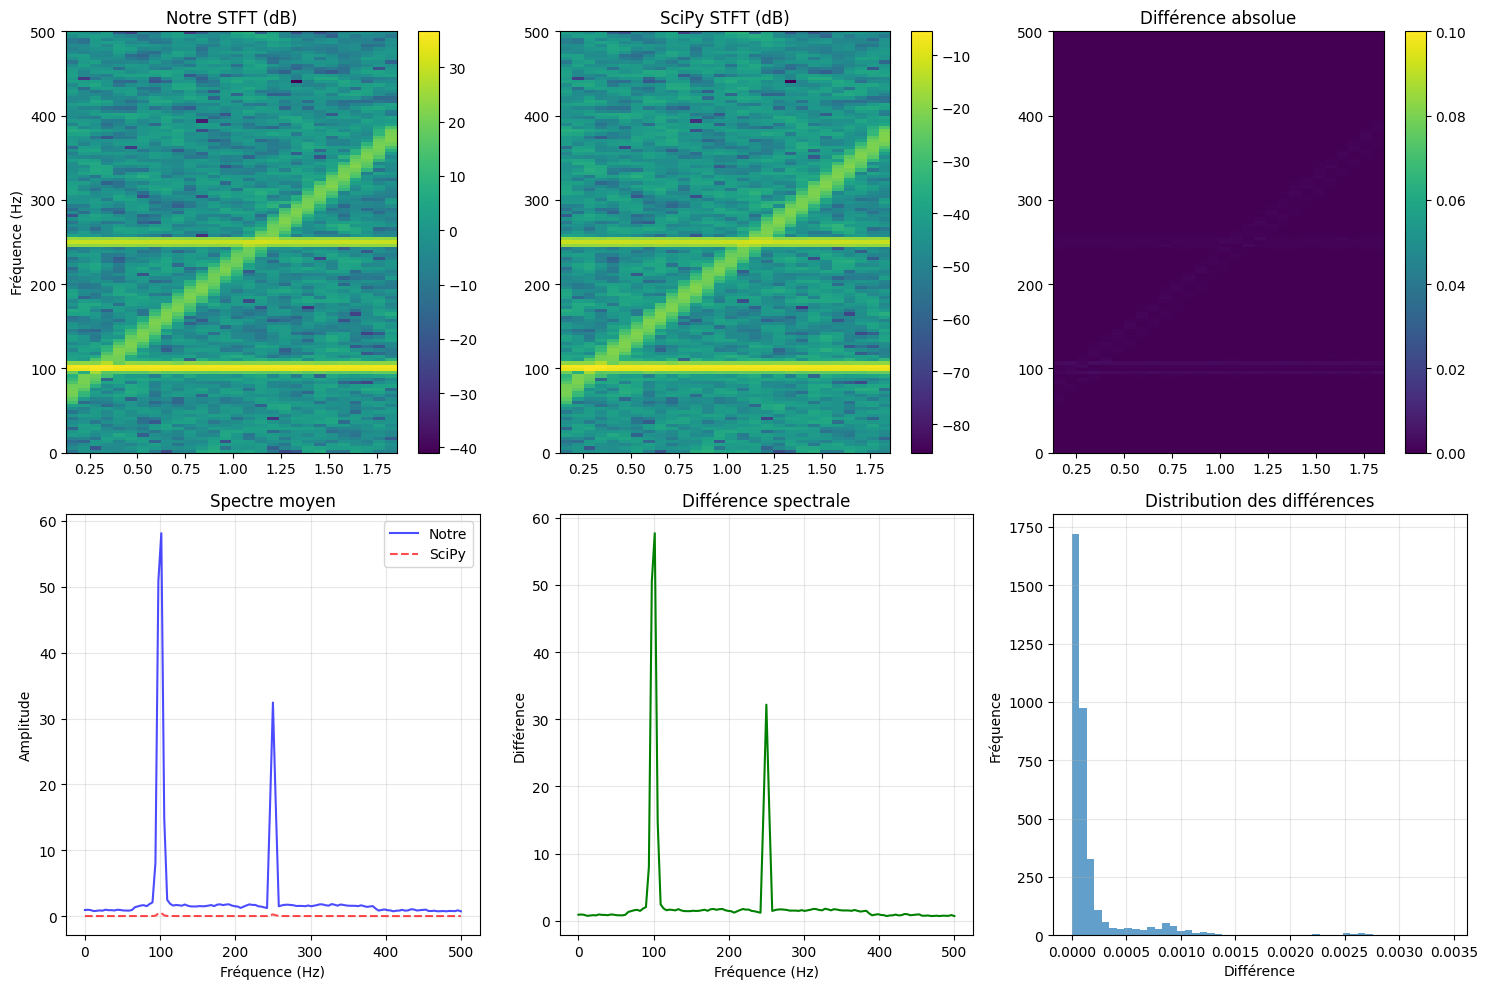


La comparaison principale a échoué. Vérification des problèmes...


In [41]:


def compare_with_scipy_stft(visualize=False):
    """
    Compare notre implémentation STFT avec celle de SciPy.
    
    Paramètres:
    -----------
    visualize : bool
        Si True, affiche des graphiques de comparaison
    """
    print("=" * 60)
    print("COMPARAISON AVEC SCIPY.SIGNAL.STFT")
    print("=" * 60)
    
    # -------------------------------------------------
    # 1. Créer un signal de test plus complexe
    # -------------------------------------------------
    fs = 1000.0
    duration = 2.0  # 2 secondes
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    
    # Signal avec plusieurs caractéristiques
    # - 2 sinusoïdes constantes
    # - 1 chirp (fréquence qui varie)
    # - Bruit blanc
    f1, f2 = 100.0, 250.0  # Hz
    x_sines = (1.0 * np.sin(2 * np.pi * f1 * t) + 
               0.5 * np.sin(2 * np.pi * f2 * t))
    
    # Chirp linéaire de 50 à 400 Hz
    f_start, f_end = 50.0, 400.0
    chirp = 0.3 * np.sin(2 * np.pi * (f_start * t + (f_end - f_start) * t**2 / (2 * duration)))
    
    # Bruit
    np.random.seed(42)
    noise = 0.1 * np.random.randn(len(t))
    
    x = x_sines + chirp + noise
    
    print(f"Signal créé: {len(x)} échantillons, {duration}s, {fs} Hz")
    print(f"Composantes: {f1} Hz + {f2} Hz + chirp {f_start}-{f_end} Hz + bruit")
    
    # -------------------------------------------------
    # 2. Paramètres STFT communs
    # -------------------------------------------------
    nperseg = 256
    hop_fraction = 0.25  # 75% overlap
    hop = int(nperseg * hop_fraction)
    nfft = nperseg  # Pas de zero-padding pour comparaison équitable
    window = 'hann'
    
    print(f"\nParamètres STFT:")
    print(f"  nperseg: {nperseg}")
    print(f"  hop_fraction: {hop_fraction} (hop: {hop} échantillons)")
    print(f"  nfft: {nfft}")
    print(f"  window: {window}")
    
    # -------------------------------------------------
    # 3. Calculer STFT avec notre implémentation
    # -------------------------------------------------
    print("\n" + "-" * 40)
    print("Notre implémentation:")
    print("-" * 40)
    
    # Avec magnitude
    M_our, freqs_our, times_our, meta_our = stft(
        x, fs, nperseg, 
        window=window,
        hop_fraction=hop_fraction,
        nfft=nfft,
        output="magnitude"
    )
    
    print(f"  Shape: {M_our.shape} (freqs × time)")
    print(f"  Fréquences: {len(freqs_our)} bins, {freqs_our[0]:.1f}-{freqs_our[-1]:.1f} Hz")
    print(f"  Temps: {len(times_our)} frames, {times_our[0]:.3f}-{times_our[-1]:.3f} s")
    
    # Avec complex (pour vérifier la phase)
    Z_our, _, _, _ = stft(
        x, fs, nperseg,
        window=window,
        hop_fraction=hop_fraction,
        nfft=nfft,
        output="complex"
    )
    
    # -------------------------------------------------
    # 4. Calculer STFT avec SciPy
    # -------------------------------------------------
    print("\n" + "-" * 40)
    print("SciPy implémentation:")
    print("-" * 40)
    
    # SciPy utilise hop en échantillons, pas en fraction
    noverlap = nperseg - hop
    
    freqs_scipy, times_scipy, Z_scipy = scipy_stft(
        x, fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        return_onesided=True,
        boundary=None,
        padded=False
    )
   
        
    # SciPy retourne (freqs, times, Z) où Z est complex (freq × time)
    M_scipy = np.abs(Z_scipy)
    
    print(f"  Shape: {Z_scipy.shape} (freqs × time)")
    print(f"  Fréquences: {len(freqs_scipy)} bins, {freqs_scipy[0]:.1f}-{freqs_scipy[-1]:.1f} Hz")
    print(f"  Temps: {len(times_scipy)} frames, {times_scipy[0]:.3f}-{times_scipy[-1]:.3f} s")
    
    
    
     # DEbug
    print("\n" + "-" * 40)
    print("DEBUG: Valeurs absolues")
    print("-" * 40)
    print(f"Notre STFT - min: {M_our.min():.6f}, max: {M_our.max():.6f}, mean: {M_our.mean():.6f}")
    print(f"SciPy STFT - min: {M_scipy.min():.6f}, max: {M_scipy.max():.6f}, mean: {M_scipy.mean():.6f}")

    # Vérifier un élément spécifique
    print(f"\nÉlément [100, 10]:")
    print(f"  Notre: {M_our[100, 10]:.6f}")
    print(f"  SciPy: {M_scipy[100, 10]:.6f}")
    print(f"  Ratio: {M_our[100, 10] / M_scipy[100, 10]:.6f}")

    # Vérifier si le ratio est constant
    sample_indices = [(50, 5), (100, 10), (80, 15)]
    print(f"\nRatios pour plusieurs éléments:")
    for i, j in sample_indices:
        ratio = M_our[i, j] / M_scipy[i, j] if M_scipy[i, j] != 0 else float('inf')
        print(f"  [{i}, {j}]: Notre={M_our[i, j]:.6f}, SciPy={M_scipy[i, j]:.6f}, Ratio={ratio:.6f}")
    
    # -------------------------------------------------
    # 5. Comparaisons quantitatives
    # -------------------------------------------------
    print("\n" + "=" * 60)
    print("COMPARAISONS QUANTITATIVES")
    print("=" * 60)
    
    comparisons = []
    
    # 5.1 Comparaison des dimensions
    dim_ok = (M_our.shape == M_scipy.shape and 
              len(freqs_our) == len(freqs_scipy) and
              len(times_our) == len(times_scipy))
    
    comparisons.append(("Dimensions", dim_ok))
    print(f"Dimensions identiques: {'✓' if dim_ok else '✗'}")
    
    if dim_ok:
        # 5.2 Comparaison des fréquences
        freq_diff = np.max(np.abs(freqs_our - freqs_scipy))
        freq_ok = freq_diff < 1e-10
        comparisons.append(("Fréquences", freq_ok))
        print(f"Fréquences identiques (max diff: {freq_diff:.2e} Hz): {'✓' if freq_ok else '✗'}")
        
        # 5.3 Comparaison des temps
        # Note: SciPy peut avoir un décalage dû au centrage des fenêtres
        time_diff = np.max(np.abs(times_our - times_scipy))
        time_ok = time_diff < (nperseg/fs)  # Tolérance d'une fenêtre
        comparisons.append(("Temps (centres)", time_ok))
        print(f"Temps similaires (max diff: {time_diff:.3f} s): {'✓' if time_ok else '✗'}")
        
        # 5.4 Comparaison des magnitudes (spectrogrammes)
        # Normaliser pour la comparaison
        M_our_norm = M_our / M_our.max() if M_our.max() > 0 else M_our
        M_scipy_norm = M_scipy / M_scipy.max() if M_scipy.max() > 0 else M_scipy
        
        # Différence relative moyenne
        mag_diff = np.mean(np.abs(M_our_norm - M_scipy_norm))
        mag_ok = mag_diff < 0.05  # 5% de différence moyenne
        
        comparisons.append(("Magnitude (diff moyenne)", mag_ok))
        print(f"Différence moyenne magnitude: {mag_diff:.4f} (< 0.05): {'✓' if mag_ok else '✗'}")
        
        # 5.5 Coefficient de corrélation
        correlation = np.corrcoef(M_our_norm.flatten(), M_scipy_norm.flatten())[0, 1]
        corr_ok = correlation > 0.95
        
        comparisons.append(("Corrélation", corr_ok))
        print(f"Coefficient de corrélation: {correlation:.4f} (> 0.95): {'✓' if corr_ok else '✗'}")
        
        # 5.6 Énergie totale
        energy_our = np.sum(M_our**2)
        energy_scipy = np.sum(M_scipy**2)
        energy_ratio = energy_our / energy_scipy if energy_scipy > 0 else 0
        energy_ok = 0.9 < energy_ratio < 1.1  # ±10%
        
        comparisons.append(("Énergie totale", energy_ok))
        print(f"Ratio d'énergie (notre/SciPy): {energy_ratio:.4f} (0.9-1.1): {'✓' if energy_ok else '✗'}")
        
        # 5.7 Vérification des pics de fréquence
        # Moyenne sur le temps pour obtenir le spectre moyen
        spectrum_our = M_our.mean(axis=1)
        spectrum_scipy = M_scipy.mean(axis=1)
        
        # Trouver les pics principaux
        peaks_our = np.argsort(spectrum_our)[-3:]  # 3 plus grands pics
        peaks_scipy = np.argsort(spectrum_scipy)[-3:]
        
        # Vérifier si les mêmes bins sont détectés comme pics
        peak_match = set(peaks_our) == set(peaks_scipy)
        
        comparisons.append(("Pics de fréquence", peak_match))
        print(f"Mêmes pics de fréquence: {'✓' if peak_match else '✗'}")
        if not peak_match:
            print(f"  Nos pics: {sorted(peaks_our)} -> {freqs_our[sorted(peaks_our)]}")
            print(f"  SciPy pics: {sorted(peaks_scipy)} -> {freqs_scipy[sorted(peaks_scipy)]}")
    
    # -------------------------------------------------
    # 6. Résumé
    # -------------------------------------------------
    print("\n" + "=" * 60)
    print("RÉSUMÉ DE LA COMPARAISON")
    print("=" * 60)
    
    passed = sum(1 for _, ok in comparisons if ok)
    total = len(comparisons)
    
    for name, ok in comparisons:
        print(f"{'✓' if ok else '✗'} {name}")
    
    print(f"\nTotal: {passed}/{total} tests de comparaison passés")
    
    if passed == total:
        print("\n🎉 EXCELLENT ! Notre STFT correspond parfaitement à SciPy !")
    elif passed >= total * 0.8:
        print("\n👍 BON ! Notre STFT est très proche de SciPy.")
    else:
        print("\n⚠️ ATTENTION : Différences significatives avec SciPy.")
    
    # -------------------------------------------------
    # 7. Visualisation (optionnelle)
    # -------------------------------------------------
    if visualize and dim_ok:
        fig, axes = plt.subplots(2, 3, figsize=(15, 10))
        
        # Spectrogramme - Notre implémentation
        im1 = axes[0, 0].imshow(20 * np.log10(M_our + 1e-10), 
                                aspect='auto', origin='lower',
                                extent=[times_our[0], times_our[-1], 
                                        freqs_our[0], freqs_our[-1]])
        axes[0, 0].set_title('Notre STFT (dB)')
        axes[0, 0].set_ylabel('Fréquence (Hz)')
        plt.colorbar(im1, ax=axes[0, 0])
        
        # Spectrogramme - SciPy
        im2 = axes[0, 1].imshow(20 * np.log10(M_scipy + 1e-10), 
                                aspect='auto', origin='lower',
                                extent=[times_scipy[0], times_scipy[-1], 
                                        freqs_scipy[0], freqs_scipy[-1]])
        axes[0, 1].set_title('SciPy STFT (dB)')
        plt.colorbar(im2, ax=axes[0, 1])
        
        # Différence
        diff = np.abs(M_our_norm - M_scipy_norm)
        im3 = axes[0, 2].imshow(diff, 
                                aspect='auto', origin='lower',
                                extent=[times_our[0], times_our[-1], 
                                        freqs_our[0], freqs_our[-1]],
                                vmin=0, vmax=0.1)
        axes[0, 2].set_title('Différence absolue')
        plt.colorbar(im3, ax=axes[0, 2])
        
        # Spectre moyen
        axes[1, 0].plot(freqs_our, spectrum_our, 'b-', label='Notre', alpha=0.7)
        axes[1, 0].plot(freqs_scipy, spectrum_scipy, 'r--', label='SciPy', alpha=0.7)
        axes[1, 0].set_title('Spectre moyen')
        axes[1, 0].set_xlabel('Fréquence (Hz)')
        axes[1, 0].set_ylabel('Amplitude')
        axes[1, 0].legend()
        axes[1, 0].grid(True, alpha=0.3)
        
        # Différence par fréquence
        freq_diff = np.abs(spectrum_our - spectrum_scipy)
        axes[1, 1].plot(freqs_our, freq_diff, 'g-')
        axes[1, 1].set_title('Différence spectrale')
        axes[1, 1].set_xlabel('Fréquence (Hz)')
        axes[1, 1].set_ylabel('Différence')
        axes[1, 1].grid(True, alpha=0.3)
        
        # Histogramme des différences
        axes[1, 2].hist(diff.flatten(), bins=50, alpha=0.7)
        axes[1, 2].set_title('Distribution des différences')
        axes[1, 2].set_xlabel('Différence')
        axes[1, 2].set_ylabel('Fréquence')
        axes[1, 2].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    print("=" * 60)
    
    return passed == total  # Retourne True si tous les tests passent

# -------------------------------------------------
# 8. Test additionnel: Différents paramètres
# -------------------------------------------------
def run_comprehensive_comparison():
    """
    Exécute plusieurs comparaisons avec différents paramètres
    """
    print("\n" + "=" * 60)
    print("COMPARAISONS COMPLÈTES AVEC DIFFÉRENTS PARAMÈTRES")
    print("=" * 60)
    
    test_cases = [
        {"nperseg": 128, "hop_fraction": 0.25, "window": "hann", "name": "Cas 1: Petit nperseg"},
        {"nperseg": 256, "hop_fraction": 0.5, "window": "hann", "name": "Cas 2: 50% overlap"},
        {"nperseg": 512, "hop_fraction": 0.75, "window": "hann", "name": "Cas 3: 75% overlap"},
        {"nperseg": 1024, "hop_fraction": 0.25, "window": "hann", "name": "Cas 4: Grand nperseg"},
    ]
    
    all_passed = True
    
    for i, params in enumerate(test_cases, 1):
        print(f"\n{i}. {params['name']}")
        print(f"   nperseg={params['nperseg']}, hop={params['hop_fraction']}")
        
        # Créer un signal simple pour ce test
        fs = 1000
        t = np.linspace(0, 1, fs, endpoint=False)
        x_test = np.sin(2 * np.pi * 100 * t) + 0.5 * np.sin(2 * np.pi * 300 * t)
        
        # Notre STFT
        M_our, freqs_our, times_our, _ = stft(
            x_test, fs,
            nperseg=params["nperseg"],
            hop_fraction=params["hop_fraction"],
            window=params["window"],
            output="magnitude"
        )
        
        # SciPy STFT
        hop = int(params["nperseg"] * params["hop_fraction"])
        noverlap = params["nperseg"] - hop
        freqs_sp, times_sp, Z_sp = scipy_stft(
            x_test, fs,
            window=params["window"],
            nperseg=params["nperseg"],
            noverlap=noverlap,
            nfft=params["nperseg"]
        )
        M_sp = np.abs(Z_sp)
        
        # Vérification rapide
        shapes_match = M_our.shape == M_sp.shape
        energy_ratio = np.sum(M_our**2) / np.sum(M_sp**2) if np.sum(M_sp**2) > 0 else 0
        energy_ok = 0.95 < energy_ratio < 1.05
        
        print(f"   Shapes match: {'✓' if shapes_match else '✗'}")
        print(f"   Energy ratio: {energy_ratio:.4f} (0.95-1.05): {'✓' if energy_ok else '✗'}")
        
        if not (shapes_match and energy_ok):
            all_passed = False
    
    print("\n" + "=" * 60)
    if all_passed:
        print("🎉 TOUS LES CAS DE TEST PASSENT !")
    else:
        print("⚠️ Certains cas ont échoué.")
    print("=" * 60)
    
    return all_passed

# -------------------------------------------------
# 9. Exécution principale
# -------------------------------------------------
if __name__ == "__main__":
    print("Démarrage de la comparaison avec SciPy...")
    
    # Comparaison détaillée avec visualisation
    comparison_ok = compare_with_scipy_stft(visualize=True)
    
    if comparison_ok:
        # Tests supplémentaires avec différents paramètres
        run_comprehensive_comparison()
    else:
        print("\nLa comparaison principale a échoué. Vérification des problèmes...")

DÉMONSTRATION VISUELLE DE L'INTÉRÊT DE LA STFT
Deux signaux simples: 100Hz (0-1s) et 50Hz (1-2s)
Signal créé: 2000 échantillons, 2.0s, 1000.0 Hz

Caractéristiques des signaux:
  • 0-1s: Sinusoïde à 100.0 Hz
  • 1-2s: Sinusoïde à 50.0 Hz
  • Bruit: présent sur toute la durée

Paramètres STFT:
  • Taille fenêtre: 256 échantillons (256.0 ms)
  • Recouvrement: 25%
  • Fenêtre: hann

Résultat STFT:
  • Dimensions: (129, 33) (fréquences × temps)
  • Résolution fréquentielle: 3.91 Hz/bin
  • Résolution temporelle: 0.064 s/frame


/tmp/ipykernel_30793/2979708767.py:158: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')
/tmp/ipykernel_30793/2979708767.py:175: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right')



CE QUE LA STFT NOUS APPREND:

1. LOCALISATION TEMPORELLE:
   • La fréquence 100.0Hz n'apparaît QUE de 0 à 1s
   • La fréquence 50.0Hz n'apparaît QUE de 1 à 2s

2. SÉPARATION FRÉQUENTIELLE:
   • Même avec du bruit, on distingue clairement 100.0Hz et 50.0Hz
   • Le bruit est réparti sur toutes les fréquences

3. RÉSOLUTION:
   • Résolution fréquentielle: 3.91 Hz
   • Résolution temporelle: 0.064 s
   • Compromis temps-fréquence visible sur les spectrogrammes

4. ROBUSTESSE:
   • Les signaux restent détectables malgré le bruit
   • La STFT permet de filtrer visuellement le bruit


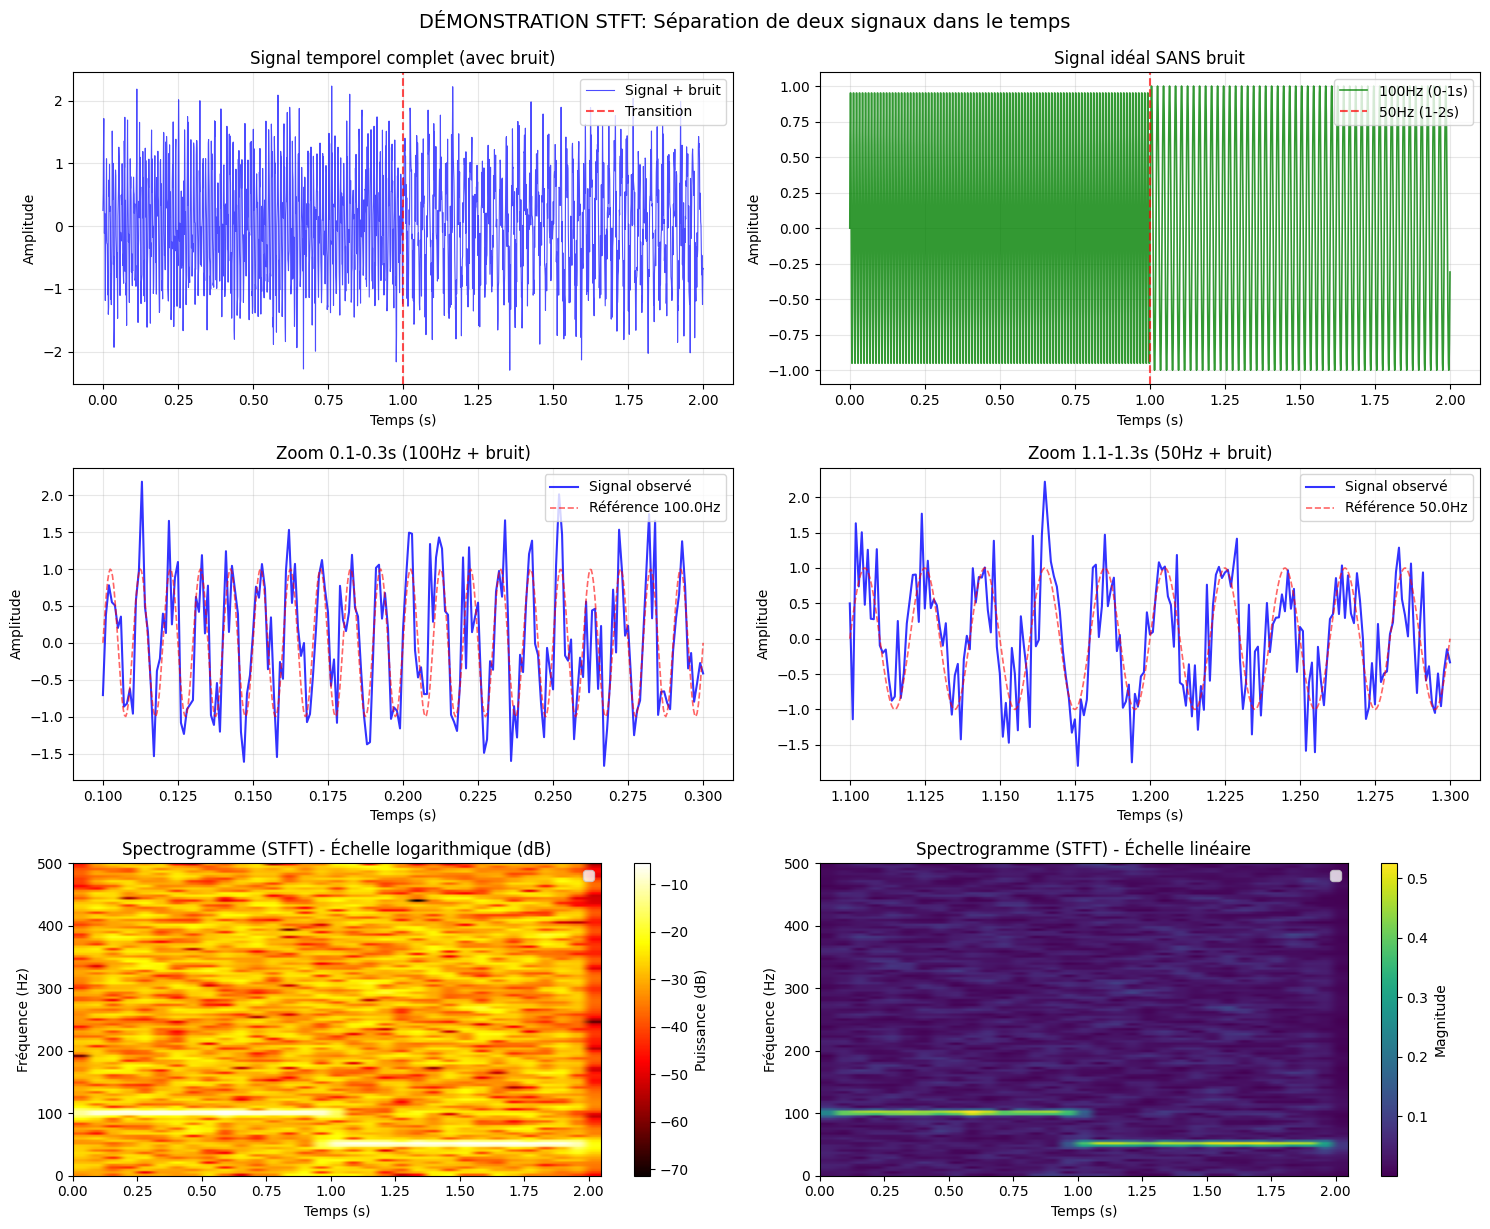

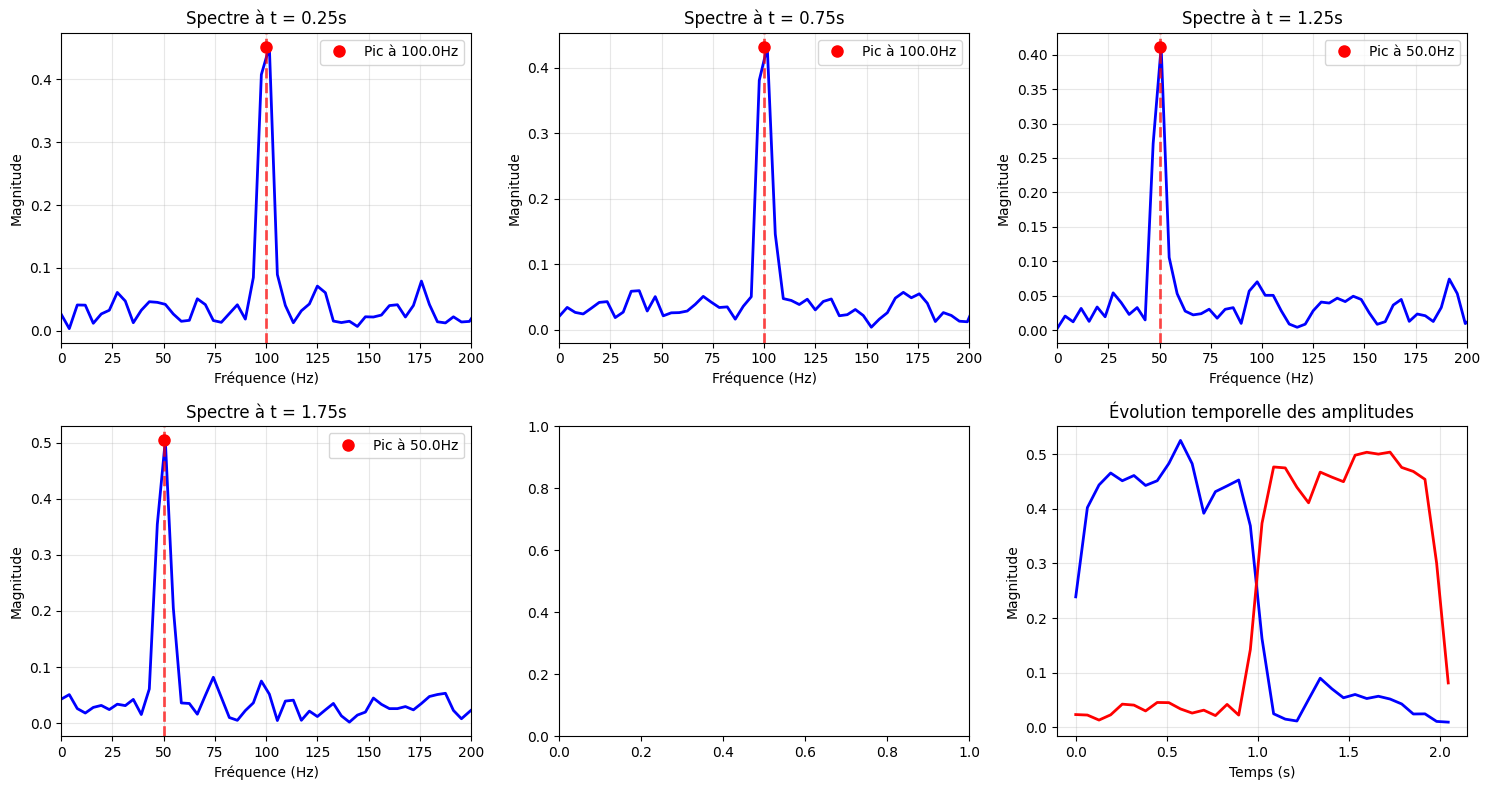

(array([ 0.24835708,  0.5186531 ,  1.27490079, ..., -1.24995432,
        -0.66931873, -0.68146832], shape=(2000,)),
 array([0.000e+00, 1.000e-03, 2.000e-03, ..., 1.997e+00, 1.998e+00,
        1.999e+00], shape=(2000,)),
 array([[0.02093336, 0.02869277, 0.01130191, ..., 0.01539343, 0.00969999,
         0.00387533],
        [0.02650546, 0.02950921, 0.02449795, ..., 0.01514074, 0.01914137,
         0.00830729],
        [0.03669381, 0.02830781, 0.01529676, ..., 0.02256056, 0.03102664,
         0.01343703],
        ...,
        [0.01058802, 0.01335851, 0.01468886, ..., 0.01988676, 0.01063331,
         0.00423045],
        [0.0073909 , 0.02079121, 0.02975869, ..., 0.03315319, 0.01840942,
         0.00273191],
        [0.00554233, 0.02660808, 0.05186319, ..., 0.03706324, 0.02081532,
         0.0015298 ]], shape=(129, 33)),
 array([  0.     ,   3.90625,   7.8125 ,  11.71875,  15.625  ,  19.53125,
         23.4375 ,  27.34375,  31.25   ,  35.15625,  39.0625 ,  42.96875,
         46.875  ,  50.7

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft as scipy_stft

def visualiser_stft_simple():
    """
    Visualisation démonstrative de l'intérêt de la STFT.
    Montre deux signaux simples (100Hz et 50Hz) à différents moments.
    """
    print("=" * 60)
    print("DÉMONSTRATION VISUELLE DE L'INTÉRÊT DE LA STFT")
    print("Deux signaux simples: 100Hz (0-1s) et 50Hz (1-2s)")
    print("=" * 60)
    
    # -------------------------------------------------
    # 1. Créer deux signaux simples
    # -------------------------------------------------
    fs = 1000.0  # Fréquence d'échantillonnage
    duration = 2.0  # 2 secondes
    t = np.linspace(0, duration, int(fs * duration), endpoint=False)
    
    # Signal 1 : 100 Hz de 0 à 1 seconde
    f1 = 100.0  # Hz
    signal1 = np.zeros_like(t)
    mask1 = t < 1.0
    signal1[mask1] = 1.0 * np.sin(2 * np.pi * f1 * t[mask1])
    
    # Signal 2 : 50 Hz de 1 à 2 secondes
    f2 = 50.0  # Hz
    signal2 = np.zeros_like(t)
    mask2 = t >= 1.0
    signal2[mask2] = 1.0 * np.sin(2 * np.pi * f2 * (t[mask2] - 1.0))
    
    # Bruit sur toute la durée
    np.random.seed(42)  # Pour la reproductibilité
    noise = 0.5 * np.random.randn(len(t))
    
    # Signal combiné avec bruit
    x = signal1 + signal2 + noise
    
    print(f"Signal créé: {len(x)} échantillons, {duration}s, {fs} Hz")
    print("\nCaractéristiques des signaux:")
    print(f"  • 0-1s: Sinusoïde à {f1} Hz")
    print(f"  • 1-2s: Sinusoïde à {f2} Hz")
    print(f"  • Bruit: présent sur toute la durée")
    
    # -------------------------------------------------
    # 2. Paramètres STFT
    # -------------------------------------------------
    nperseg = 256  # Taille de la fenêtre
    hop_fraction = 0.25  # 75% de recouvrement
    hop = int(nperseg * hop_fraction)
    nfft = nperseg
    window = 'hann'
    
    print(f"\nParamètres STFT:")
    print(f"  • Taille fenêtre: {nperseg} échantillons ({nperseg/fs*1000:.1f} ms)")
    print(f"  • Recouvrement: {hop_fraction*100:.0f}%")
    print(f"  • Fenêtre: {window}")
    
    # -------------------------------------------------
    # 3. Calculer la STFT
    # -------------------------------------------------
    noverlap = nperseg - hop
    freqs, times, Z = scipy_stft(
        x, fs,
        window=window,
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        return_onesided=True
    )
    
    M = np.abs(Z)  # Magnitude
    
    print(f"\nRésultat STFT:")
    print(f"  • Dimensions: {M.shape} (fréquences × temps)")
    print(f"  • Résolution fréquentielle: {freqs[1]-freqs[0]:.2f} Hz/bin")
    print(f"  • Résolution temporelle: {times[1]-times[0]:.3f} s/frame")
    
    # -------------------------------------------------
    # 4. Visualisations principales
    # -------------------------------------------------
    fig, axes = plt.subplots(3, 2, figsize=(15, 12))
    
    # 4.1 Signal temporel complet
    ax = axes[0, 0]
    ax.plot(t, x, 'b-', alpha=0.7, linewidth=0.8)
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Amplitude')
    ax.set_title('Signal temporel complet (avec bruit)')
    ax.grid(True, alpha=0.3)
    ax.axvline(x=1.0, color='r', linestyle='--', alpha=0.7, linewidth=1.5)
    ax.legend(['Signal + bruit', 'Transition'], loc='upper right')
    
    # 4.2 Signal temporel sans bruit (référence)
    ax = axes[0, 1]
    signal_clean = signal1 + signal2
    ax.plot(t, signal_clean, 'g-', alpha=0.8, linewidth=1.2)
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Amplitude')
    ax.set_title('Signal idéal SANS bruit')
    ax.grid(True, alpha=0.3)
    ax.axvline(x=1.0, color='r', linestyle='--', alpha=0.7, linewidth=1.5)
    ax.legend(['100Hz (0-1s)', '50Hz (1-2s)', 'Transition'], loc='upper right')
    
    # 4.3 Zoom sur le début (100Hz)
    ax = axes[1, 0]
    zoom_start = 0.1  # Démarrer un peu après 0 pour éviter les transitoires
    zoom_end = 0.3
    mask_zoom1 = (t >= zoom_start) & (t <= zoom_end)
    ax.plot(t[mask_zoom1], x[mask_zoom1], 'b-', alpha=0.8, linewidth=1.5)
    
    # Ajouter une sinusoïde de référence
    t_ref = np.linspace(zoom_start, zoom_end, 500)
    sin_ref = 1.0 * np.sin(2 * np.pi * f1 * t_ref)
    ax.plot(t_ref, sin_ref, 'r--', alpha=0.6, linewidth=1.2)
    
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Amplitude')
    ax.set_title(f'Zoom 0.1-0.3s (100Hz + bruit)')
    ax.grid(True, alpha=0.3)
    ax.legend(['Signal observé', f'Référence {f1}Hz'], loc='upper right')
    
    # 4.4 Zoom sur la fin (50Hz)
    ax = axes[1, 1]
    zoom_start = 1.1  # Démarrer un peu après la transition
    zoom_end = 1.3
    mask_zoom2 = (t >= zoom_start) & (t <= zoom_end)
    ax.plot(t[mask_zoom2], x[mask_zoom2], 'b-', alpha=0.8, linewidth=1.5)
    
    # Ajouter une sinusoïde de référence
    t_ref = np.linspace(zoom_start, zoom_end, 500)
    sin_ref = 1.0 * np.sin(2 * np.pi * f2 * (t_ref - 1.0))
    ax.plot(t_ref, sin_ref, 'r--', alpha=0.6, linewidth=1.2)
    
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Amplitude')
    ax.set_title(f'Zoom 1.1-1.3s (50Hz + bruit)')
    ax.grid(True, alpha=0.3)
    ax.legend(['Signal observé', f'Référence {f2}Hz'], loc='upper right')
    
    # 4.5 Spectrogramme (STFT) - version en dB
    ax = axes[2, 0]
    M_db = 20 * np.log10(M + 1e-10)  # Convertir en dB
    im = ax.imshow(M_db, aspect='auto', origin='lower',
                   extent=[times[0], times[-1], freqs[0], freqs[-1]],
                   cmap='hot')
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Fréquence (Hz)')
    ax.set_title('Spectrogramme (STFT) - Échelle logarithmique (dB)')
    
    # Ajouter des lignes pour les fréquences attendues
    #ax.axhline(y=f1, color='cyan', linestyle='-', alpha=0.8, linewidth=2, label=f'{f1}Hz')
    #ax.axhline(y=f2, color='lime', linestyle='-', alpha=0.8, linewidth=2, label=f'{f2}Hz')
    #ax.axvline(x=1.0, color='white', linestyle='--', alpha=0.9, linewidth=2)
    
    ax.legend(loc='upper right')
    plt.colorbar(im, ax=ax, label='Puissance (dB)')
    
    # 4.6 Spectrogramme (STFT) - version linéaire
    ax = axes[2, 1]
    im = ax.imshow(M, aspect='auto', origin='lower',
                   extent=[times[0], times[-1], freqs[0], freqs[-1]],
                   cmap='viridis')
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Fréquence (Hz)')
    ax.set_title('Spectrogramme (STFT) - Échelle linéaire')
    
    # Ajouter des lignes pour les fréquences attendues
    #ax.axhline(y=f1, color='white', linestyle='-', alpha=0.8, linewidth=2, label=f'{f1}Hz')
    #ax.axhline(y=f2, color='red', linestyle='-', alpha=0.8, linewidth=2, label=f'{f2}Hz')
    #ax.axvline(x=1.0, color='yellow', linestyle='--', alpha=0.9, linewidth=2)
    
    ax.legend(loc='upper right')
    plt.colorbar(im, ax=ax, label='Magnitude')
    
    plt.tight_layout()
    plt.suptitle('DÉMONSTRATION STFT: Séparation de deux signaux dans le temps', 
                 fontsize=14, y=1.02)
    
    # -------------------------------------------------
    # 5. Visualisation complémentaire: spectres à différents instants
    # -------------------------------------------------
    fig2, axes2 = plt.subplots(2, 3, figsize=(15, 8))
    
    # Choisir des instants spécifiques
    time_points = [0.25, 0.75, 1.25, 1.75]  # secondes
    time_indices = [np.argmin(np.abs(times - tp)) for tp in time_points]
    
    for idx, (tp, ti) in enumerate(zip(time_points, time_indices)):
        ax = axes2[idx // 3, idx % 3]
        ax.plot(freqs, M[:, ti], 'b-', linewidth=2)
        ax.set_xlabel('Fréquence (Hz)')
        ax.set_ylabel('Magnitude')
        ax.set_title(f'Spectre à t = {tp:.2f}s')
        ax.grid(True, alpha=0.3)
        
        # Marquer les fréquences attendues
        if tp < 1.0:
            ax.axvline(x=f1, color='red', linestyle='--', alpha=0.7, linewidth=2)
            ax.plot(f1, M[np.argmin(np.abs(freqs - f1)), ti], 'ro', markersize=8, label=f'Pic à {f1}Hz')
        else:
            ax.axvline(x=f2, color='red', linestyle='--', alpha=0.7, linewidth=2)
            ax.plot(f2, M[np.argmin(np.abs(freqs - f2)), ti], 'ro', markersize=8, label=f'Pic à {f2}Hz')
        
        ax.legend(loc='upper right')
        ax.set_xlim([0, 200])  # Zoom sur les basses fréquences
    
    # 6ème sous-graphique: évolution de l'amplitude à 100Hz et 50Hz
    ax = axes2[1, 2]
    # Trouver les indices des fréquences les plus proches
    idx_f1 = np.argmin(np.abs(freqs - f1))
    idx_f2 = np.argmin(np.abs(freqs - f2))
    
    ax.plot(times, M[idx_f1, :], 'b-', linewidth=2, label=f'100Hz')
    ax.plot(times, M[idx_f2, :], 'r-', linewidth=2, label=f'50Hz')
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel('Magnitude')
    ax.set_title('Évolution temporelle des amplitudes')
    ax.grid(True, alpha=0.3)
    #ax.axvline(x=1.0, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
    #ax.legend(loc='upper right')
    
    plt.tight_layout()
    
    # -------------------------------------------------
    # 6. Résumé et explication
    # -------------------------------------------------
    print("\n" + "=" * 60)
    print("CE QUE LA STFT NOUS APPREND:")
    print("=" * 60)
    print("\n1. LOCALISATION TEMPORELLE:")
    print(f"   • La fréquence {f1}Hz n'apparaît QUE de 0 à 1s")
    print(f"   • La fréquence {f2}Hz n'apparaît QUE de 1 à 2s")
    
    print("\n2. SÉPARATION FRÉQUENTIELLE:")
    print(f"   • Même avec du bruit, on distingue clairement {f1}Hz et {f2}Hz")
    print("   • Le bruit est réparti sur toutes les fréquences")
    
    print("\n3. RÉSOLUTION:")
    print(f"   • Résolution fréquentielle: {freqs[1]-freqs[0]:.2f} Hz")
    print(f"   • Résolution temporelle: {times[1]-times[0]:.3f} s")
    print("   • Compromis temps-fréquence visible sur les spectrogrammes")
    
    print("\n4. ROBUSTESSE:")
    print("   • Les signaux restent détectables malgré le bruit")
    print("   • La STFT permet de filtrer visuellement le bruit")
    
    plt.show()
    
    return x, t, M, freqs, times

# Pour exécuter:
visualiser_stft_simple()